# Jacobian-Based Stability Analysis of Human Posture

## Importing Python Libraries

In [228]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

## Reading Posture Data For 2 Patients

In [229]:
p1=pd.read_csv(r'C:\Users\hp\Downloads\Patient1.csv')

In [230]:
p2=pd.read_csv(r'C:\Users\hp\Downloads\Patient2.csv')

## Functional Programming

### 4 Test Split

In [231]:
def patient_test_type_split(df): 
    OH=df[["X1","Z1"]][20:].reset_index(drop=True)
    OH.columns=["X","Z"]
    CH=df[["X3","Z3"]][20:].reset_index(drop=True)
    CH.columns=["X","Z"]
    OS=df[["X5","Z5"]][20:].reset_index(drop=True)
    OS.columns=["X","Z"]
    CS=df[["X7","Z7"]][20:].reset_index(drop=True)
    CS.columns=["X","Z"]
    return (OH,CH,OS,CS)

### Independent Velocity

In [232]:
def independent_velocity(df): 
    for i in df["X"].index: 
        if i!=0 and i!=len(df)-1:            
            df.loc[i,"Vx"]=(df["X"][i+1] - df["X"][i-1])/(2*0.01)
        elif i==0: 
            df.loc[i,"Vx"]=(df["X"][i+1] - df["X"][i])/0.01
        else: 
            df.loc[i,"Vx"]=(df["X"][i] - df["X"][i-1])/0.01 
    for i in df["Z"].index: 
        if i!=0 and i!=len(df)-1:            
            df.loc[i,"Vz"]=(df["Z"][i+1] - df["Z"][i-1])/(2*0.01)
        elif i==0: 
            df.loc[i,"Vz"]=(df["Z"][i+1] - df["Z"][i])/0.01
        else: 
            df.loc[i,"Vz"]=(df["Z"][i] - df["Z"][i-1])/0.01 
    return df

### Dependent Velocity

In [233]:
def dependent_velocity_x(df): 
    feature=df[["X","Z"]]
    label=df["Vx"] 
    scaler = StandardScaler()
    scaled_feature = scaler.fit_transform(feature)
    model = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10)
    model.fit(scaled_feature, label)
    importance=model.feature_importances_
    output=model.predict(scaled_feature) 
    df["dVx"]=output
    mae=mean_absolute_error(label,output)
    mse=mean_squared_error(label,output)
    rmse=mse**0.5
    r2=r2_score(label,output)
    return (df,importance,mae,mse,rmse,r2) 

In [234]:
def dependent_velocity_z(df): 
    feature=df[["X","Z"]]
    label=df["Vz"] 
    scaler = StandardScaler()
    scaled_feature = scaler.fit_transform(feature)
    model = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10)
    model.fit(scaled_feature, label)
    importance=model.feature_importances_
    output=model.predict(scaled_feature) 
    df["dVz"]=output
    mae=mean_absolute_error(label,output)
    mse=mean_squared_error(label,output)
    rmse=mse**0.5
    r2=r2_score(label,output)
    return (df,importance,mae,mse,rmse,r2)

### Partial Derivative & Jacobian Matrix 

In [235]:
def partial_derivative(df): 
    for (i,j) in list(zip(df["dVx"].index,df["X"].index)): 
        if i!=0 and i!=len(df)-1:            
            df.loc[i,"Vx/X"]=(df["dVx"][i+1] - df["dVx"][i-1])/(df["X"][i+1] - df["X"][i-1])
        elif i==0: 
            df.loc[i,"Vx/X"]=(df["dVx"][i+1] - df["dVx"][i])/(df["X"][i+1] - df["X"][i])
        else: 
           df.loc[i,"Vx/X"]=(df["dVx"][i] - df["dVx"][i-1])/(df["X"][i] - df["X"][i-1])

    for (i,j) in list(zip(df["dVz"].index,df["X"].index)): 
        if i!=0 and i!=len(df)-1:            
            df.loc[i,"Vz/X"]=(df["dVz"][i+1] - df["dVz"][i-1])/(df["X"][i+1] - df["X"][i-1])
        elif i==0: 
            df.loc[i,"Vz/X"]=(df["dVz"][i+1] - df["dVz"][i])/(df["X"][i+1] - df["X"][i])
        else: 
           df.loc[i,"Vz/X"]=(df["dVz"][i] - df["dVz"][i-1])/(df["X"][i] - df["X"][i-1])

    for (i,j) in list(zip(df["dVx"].index,df["Z"].index)): 
        if i!=0 and i!=len(df)-1:            
            df.loc[i,"Vx/Z"]=(df["dVx"][i+1] - df["dVx"][i-1])/(df["Z"][i+1] - df["Z"][i-1])
        elif i==0: 
            df.loc[i,"Vx/Z"]=(df["dVx"][i+1] - df["dVx"][i])/(df["Z"][i+1] - df["Z"][i])
        else: 
           df.loc[i,"Vx/Z"]=(df["dVx"][i] - df["dVx"][i-1])/(df["Z"][i] - df["Z"][i-1]) 

    for (i,j) in list(zip(df["dVz"].index,df["Z"].index)): 
        if i!=0 and i!=len(df)-1:            
            df.loc[i,"Vz/Z"]=(df["dVz"][i+1] - df["dVz"][i-1])/(df["Z"][i+1] - df["Z"][i-1])
        elif i==0: 
            df.loc[i,"Vz/Z"]=(df["dVz"][i+1] - df["dVz"][i])/(df["Z"][i+1] - df["Z"][i])
        else: 
           df.loc[i,"Vz/Z"]=(df["dVz"][i] - df["dVz"][i-1])/(df["Z"][i] - df["Z"][i-1]) 
    return df

### Stability Analysis

In [236]:
def classify_by_eigenvalues(df):
    balances = []
    eig_realparts_pos = 0
    for (a,b,c,d) in zip(df["Vx/X"],df["Vx/Z"],df["Vz/X"],df["Vz/Z"]):
        J = np.array([[a, b],[c, d]], dtype=float)
        vals = np.linalg.eigvals(J)
        if vals[0]*vals[1] < 0:
            balances.append("SADDLE")
        else:
            if vals[0]<0 and vals[1]<0:
                balances.append("STABLE")
            elif vals[0]>0 and vals[1]>0:
                balances.append("UNSTABLE")
            else:
                tr = a + d
                balances.append("STABLE" if tr < 0 else "UNSTABLE")
    df["Balance"] = balances
    return df

### Visualizations

In [237]:
def graphs(df): 
    fig, axes = plt.subplots(nrows=2,ncols=2,figsize=(10,8),dpi=200)
    fig.suptitle("Visualizations")
    
    sns.scatterplot(data=df, x="X", y="Vx", s=5, alpha=0.4,ax=axes[0,0],label="f(x)")
    sns.scatterplot(data=df, x="X", y="dVx", s=5, alpha=0.4,ax=axes[0,0],label="f(x,z)")
    axes[0,0].set_title("Cross Coupling in Vx")
    axes[0,0].set_xlabel("x")
    axes[0,0].set_ylabel("Vx") 
    axes[0,0].legend()

    sns.scatterplot(data=df, x="Z", y="Vz", s=5, alpha=0.4,ax=axes[0,1],label="f(z)")
    sns.scatterplot(data=df, x="Z", y="dVz", s=5, alpha=0.4,ax=axes[0,1],label="f(x,z)")
    axes[0,1].set_title("Cross Coupling in Vz")
    axes[0,1].set_xlabel("z")
    axes[0,1].set_ylabel("Vz")
    axes[0,1].legend()

    mean_jacobian=np.array([df["Vx/X"].mean(),df["Vz/X"].mean(),df["Vx/Z"].mean(),df["Vz/Z"].mean()]).reshape(2,2)
    sns.heatmap(mean_jacobian,linewidths=0.5,annot=True,fmt='.2e',xticklabels=['x', 'z'],yticklabels=['Vx', 'Vz'],ax=axes[1,0])
    axes[1,0].set_title("Mean Jacobian Matrix")

    sns.scatterplot(data=df, x="X", y="Z", s=5, alpha=0.7,hue='Balance',ax=axes[1,1])
    axes[1,1].set_title("Posture Distribution")
    axes[1,1].set_xlabel("x")
    axes[1,1].set_ylabel("y")
    axes[1,1].legend(loc="lower right")
    
    plt.tight_layout()
    plt.show()

## Patient 1 

In [238]:
test_types=patient_test_type_split(p1)

### Eyes Open & Firm Surface

In [239]:
ind_vel=independent_velocity(test_types[0])
dep_vel_x=dependent_velocity_x(ind_vel)
print(f'Vx (x,y) = {dep_vel_x[1]}')
print(f'Mean Absolute Error: {dep_vel_x[2]}')
print(f'Mean Square Error: {dep_vel_x[3]}')
print(f'Root Mean Square Error: {dep_vel_x[4]}')
print(f'R^2 Score: {dep_vel_x[5]}')

Vx (x,y) = [0.44731902 0.55268098]
Mean Absolute Error: 0.0002930755209103075
Mean Square Error: 1.3742382320197526e-07
Root Mean Square Error: 0.00037070719335072965
R^2 Score: 0.2427094247171384


In [240]:
dep_vel_z=dependent_velocity_z(dep_vel_x[0])
print(f'Vz (x,y) = {dep_vel_z[1]}')
print(f'Mean Absolute Error: {dep_vel_z[2]}')
print(f'Mean Square Error: {dep_vel_z[3]}')
print(f'Root Mean Square Error: {dep_vel_z[4]}')
print(f'R^2 Score: {dep_vel_z[5]}')

Vz (x,y) = [0.55715485 0.44284515]
Mean Absolute Error: 0.00024589181855705377
Mean Square Error: 9.713116689853173e-08
Root Mean Square Error: 0.0003116587346738925
R^2 Score: 0.2148120826190547


In [241]:
jacobian=partial_derivative(dep_vel_z[0])
output=classify_by_eigenvalues(jacobian)

In [242]:
output

,X,Z,Vx,Vz,dVx,dVz,Vx/X,Vz/X,Vx/Z,Vz/Z,Balance
0,-2.944387e-05,0.000040,0.000459,0.000065,0.000226,0.000015,-3.662199,-11.362141,-26.013901,-80.709329,STABLE
1,-2.485259e-05,0.000040,0.000582,-0.000167,0.000209,-0.000037,-1.498594,-10.085410,5.215925,35.102726,SADDLE
2,-1.781103e-05,0.000036,0.000791,-0.000548,0.000208,-0.000102,-3.824939,-3.442965,5.522753,4.971228,UNSTABLE
3,-9.035835e-06,0.000029,0.000917,-0.000770,0.000148,-0.000091,-3.714034,3.069264,4.422101,-3.654407,STABLE
4,5.260390e-07,0.000021,0.000939,-0.000859,0.000140,-0.000046,8.284167,2.727983,-9.058237,-2.982885,UNSTABLE
...,...,...,...,...,...,...,...,...,...,...,...
2971,-1.012728e-05,0.000027,-0.000309,-0.000035,-0.000055,0.000016,3.756171,1.441751,33.170546,12.732026,SADDLE
2972,-1.328846e-05,0.000027,-0.000323,-0.000094,-0.000073,-0.000023,2.007641,8.488632,6.862526,29.015871,UNSTABLE
2973,-1.658136e-05,0.000025,-0.000336,-0.000186,-0.000068,-0.000038,-9.991825,5.955657,-18.064904,10.767640,UNSTABLE
2974,-2.000066e-05,0.000023,-0.000339,-0.000300,-0.000006,-0.000063,3.154183,7.584089,3.563506,8.568288,SADDLE


In [243]:
output["Balance"].value_counts()

Balance
STABLE      1127
UNSTABLE    1086
SADDLE       763
Name: count, dtype: int64

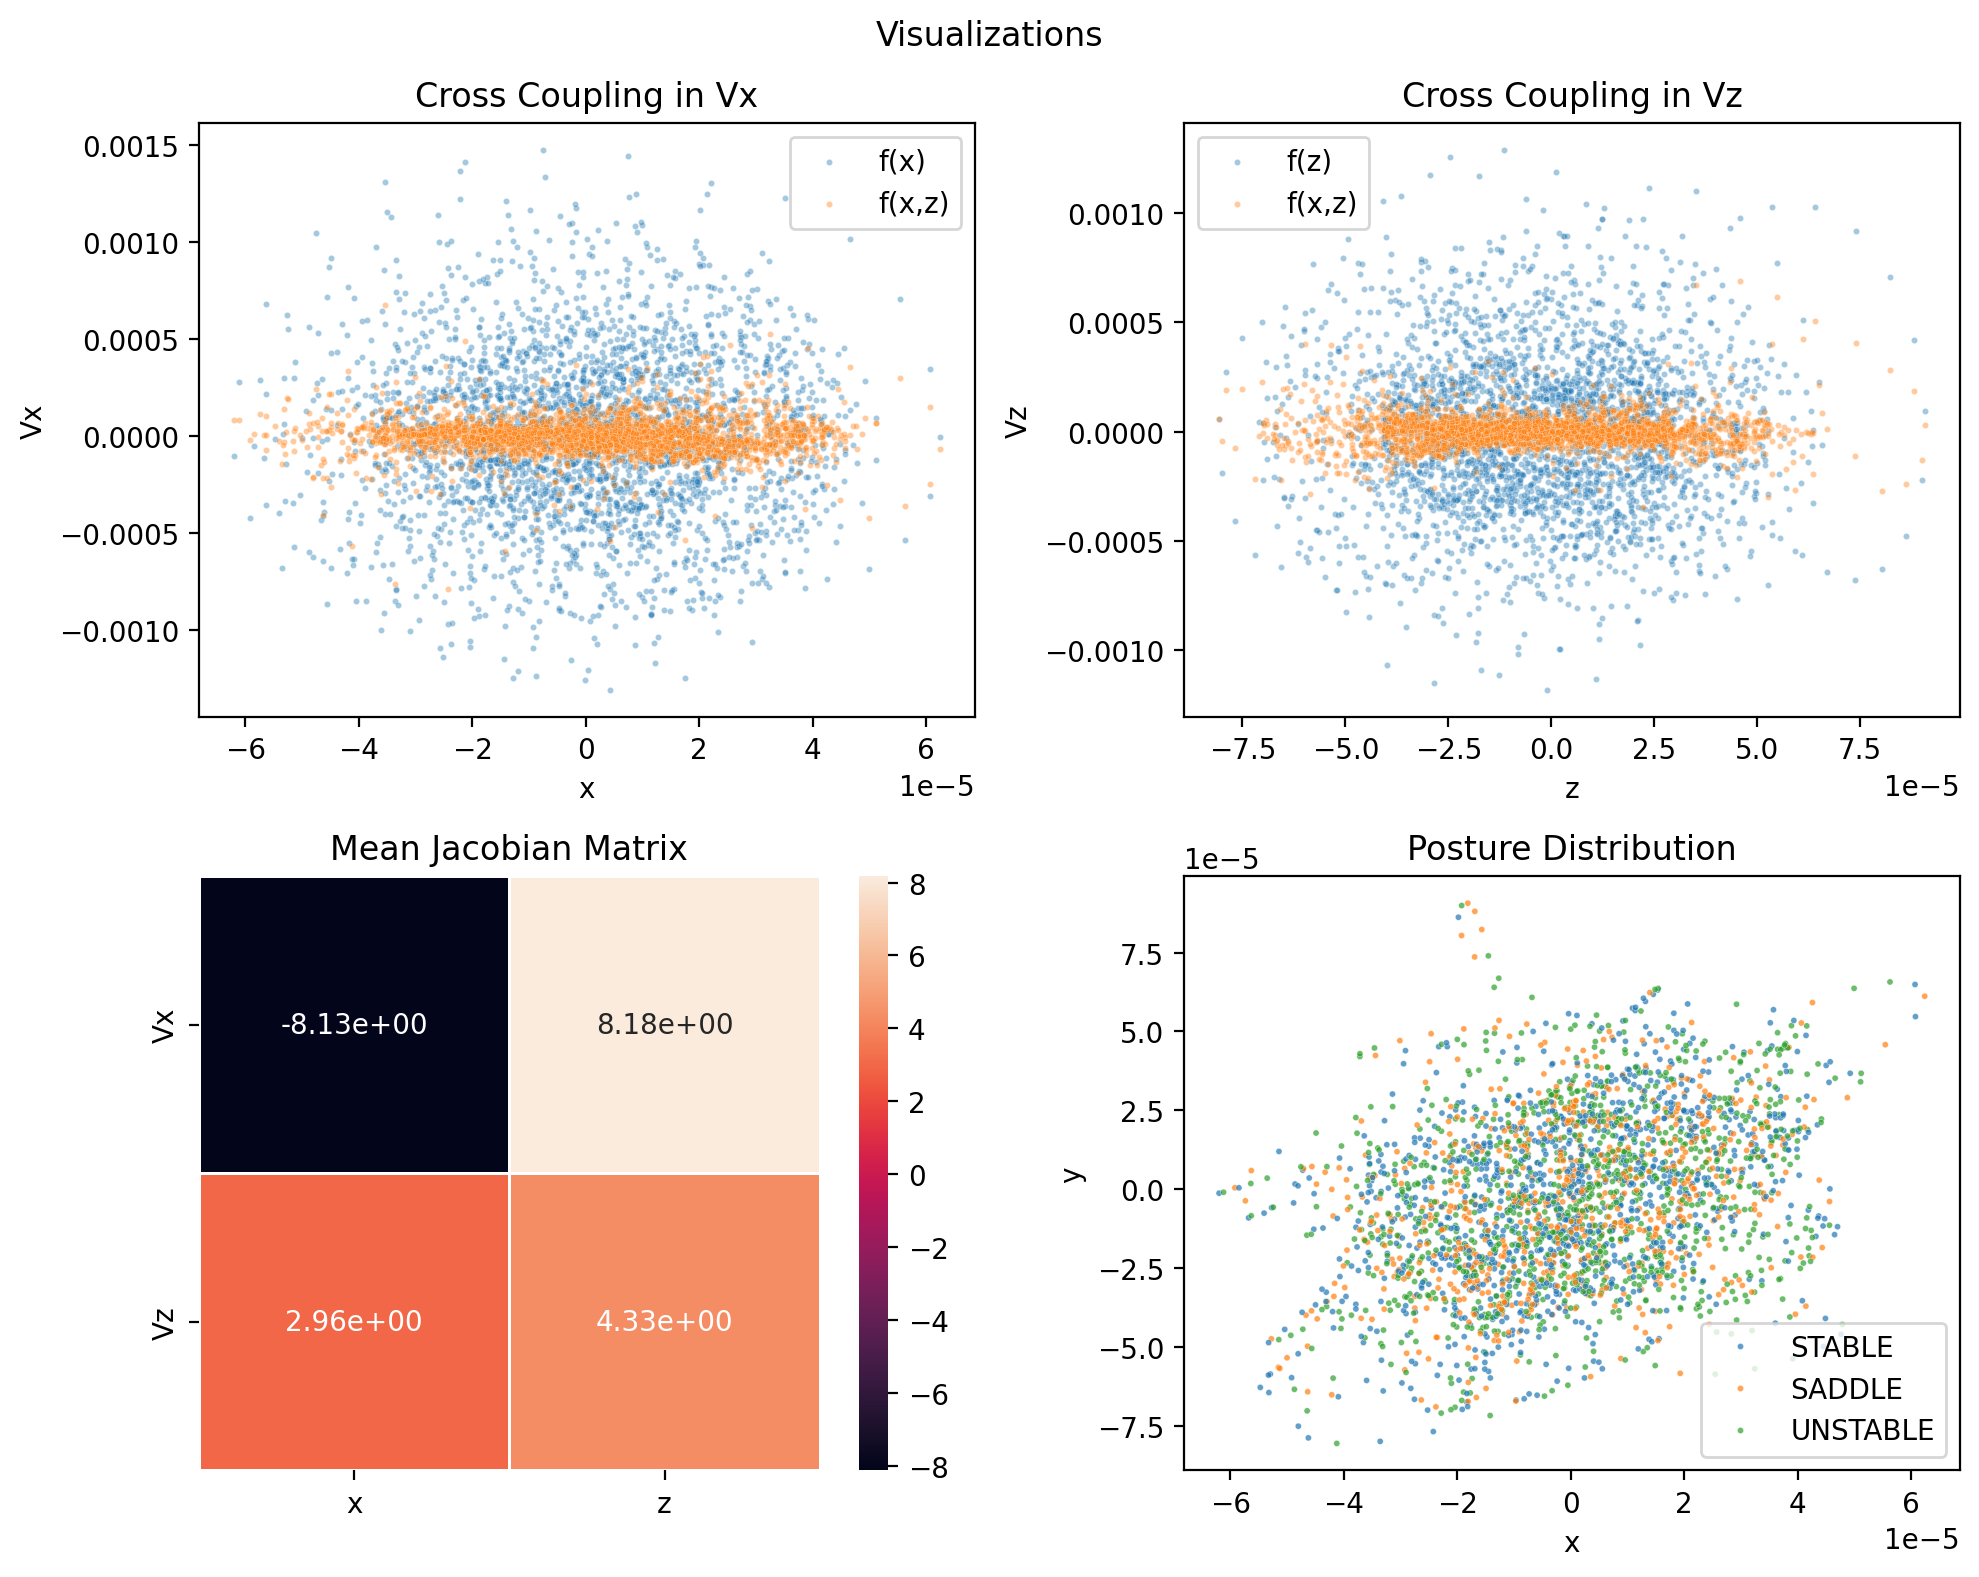

In [244]:
graphs(output)

### Eyes Closed & Firm Surface

In [245]:
ind_vel=independent_velocity(test_types[1])
dep_vel_x=dependent_velocity_x(ind_vel)
print(f'Vx (x,y) = {dep_vel_x[1]}')
print(f'Mean Absolute Error: {dep_vel_x[2]}')
print(f'Mean Square Error: {dep_vel_x[3]}')
print(f'Root Mean Square Error: {dep_vel_x[4]}')
print(f'R^2 Score: {dep_vel_x[5]}')

Vx (x,y) = [0.45076769 0.54923231]
Mean Absolute Error: 0.0003359406340172613
Mean Square Error: 1.7727542174359304e-07
Root Mean Square Error: 0.00042104087894596773
R^2 Score: 0.1959663995772425


In [246]:
dep_vel_z=dependent_velocity_z(dep_vel_x[0])
print(f'Vz (x,y) = {dep_vel_z[1]}')
print(f'Mean Absolute Error: {dep_vel_z[2]}')
print(f'Mean Square Error: {dep_vel_z[3]}')
print(f'Root Mean Square Error: {dep_vel_z[4]}')
print(f'R^2 Score: {dep_vel_z[5]}')

Vz (x,y) = [0.53750272 0.46249728]
Mean Absolute Error: 0.00026248463532338093
Mean Square Error: 1.0770875681552281e-07
Root Mean Square Error: 0.00032819012297069945
R^2 Score: 0.27090934672336986


In [247]:
jacobian=partial_derivative(dep_vel_z[0])
output=classify_by_eigenvalues(jacobian)

In [248]:
output

,X,Z,Vx,Vz,dVx,dVz,Vx/X,Vz/X,Vx/Z,Vz/Z,Balance
0,0.000009,7.636434e-05,0.000103,-0.000194,-0.000085,-0.000237,102.980529,-94.651463,-54.905999,50.465201,UNSTABLE
1,0.000010,7.442547e-05,0.000133,-0.000319,0.000022,-0.000335,63.338903,-93.111558,-26.489221,38.940565,SADDLE
2,0.000011,6.998493e-05,0.000179,-0.000532,0.000084,-0.000485,19.745198,-55.173150,-6.628902,18.522855,UNSTABLE
3,0.000013,6.379044e-05,0.000194,-0.000667,0.000092,-0.000532,13.075998,-1.007745,-3.811301,0.293730,SADDLE
4,0.000015,5.665011e-05,0.000181,-0.000723,0.000135,-0.000489,-29.360789,94.265540,7.344137,-23.579032,STABLE
...,...,...,...,...,...,...,...,...,...,...,...
2971,0.000031,-1.253850e-05,0.000562,0.000425,0.000184,0.000067,-5.826522,4.017608,-7.695783,5.306534,STABLE
2972,0.000036,-7.982867e-06,0.000466,0.000460,0.000136,0.000150,-9.393202,9.931472,-9.511926,10.056999,SADDLE
2973,0.000040,-3.337286e-06,0.000352,0.000437,0.000097,0.000160,-5.808507,8.038473,-4.682663,6.480402,UNSTABLE
2974,0.000043,7.501081e-07,0.000243,0.000356,0.000095,0.000207,-10.452937,15.721598,-7.127337,10.719775,UNSTABLE


In [249]:
output["Balance"].value_counts()

Balance
STABLE      1173
UNSTABLE    1058
SADDLE       745
Name: count, dtype: int64

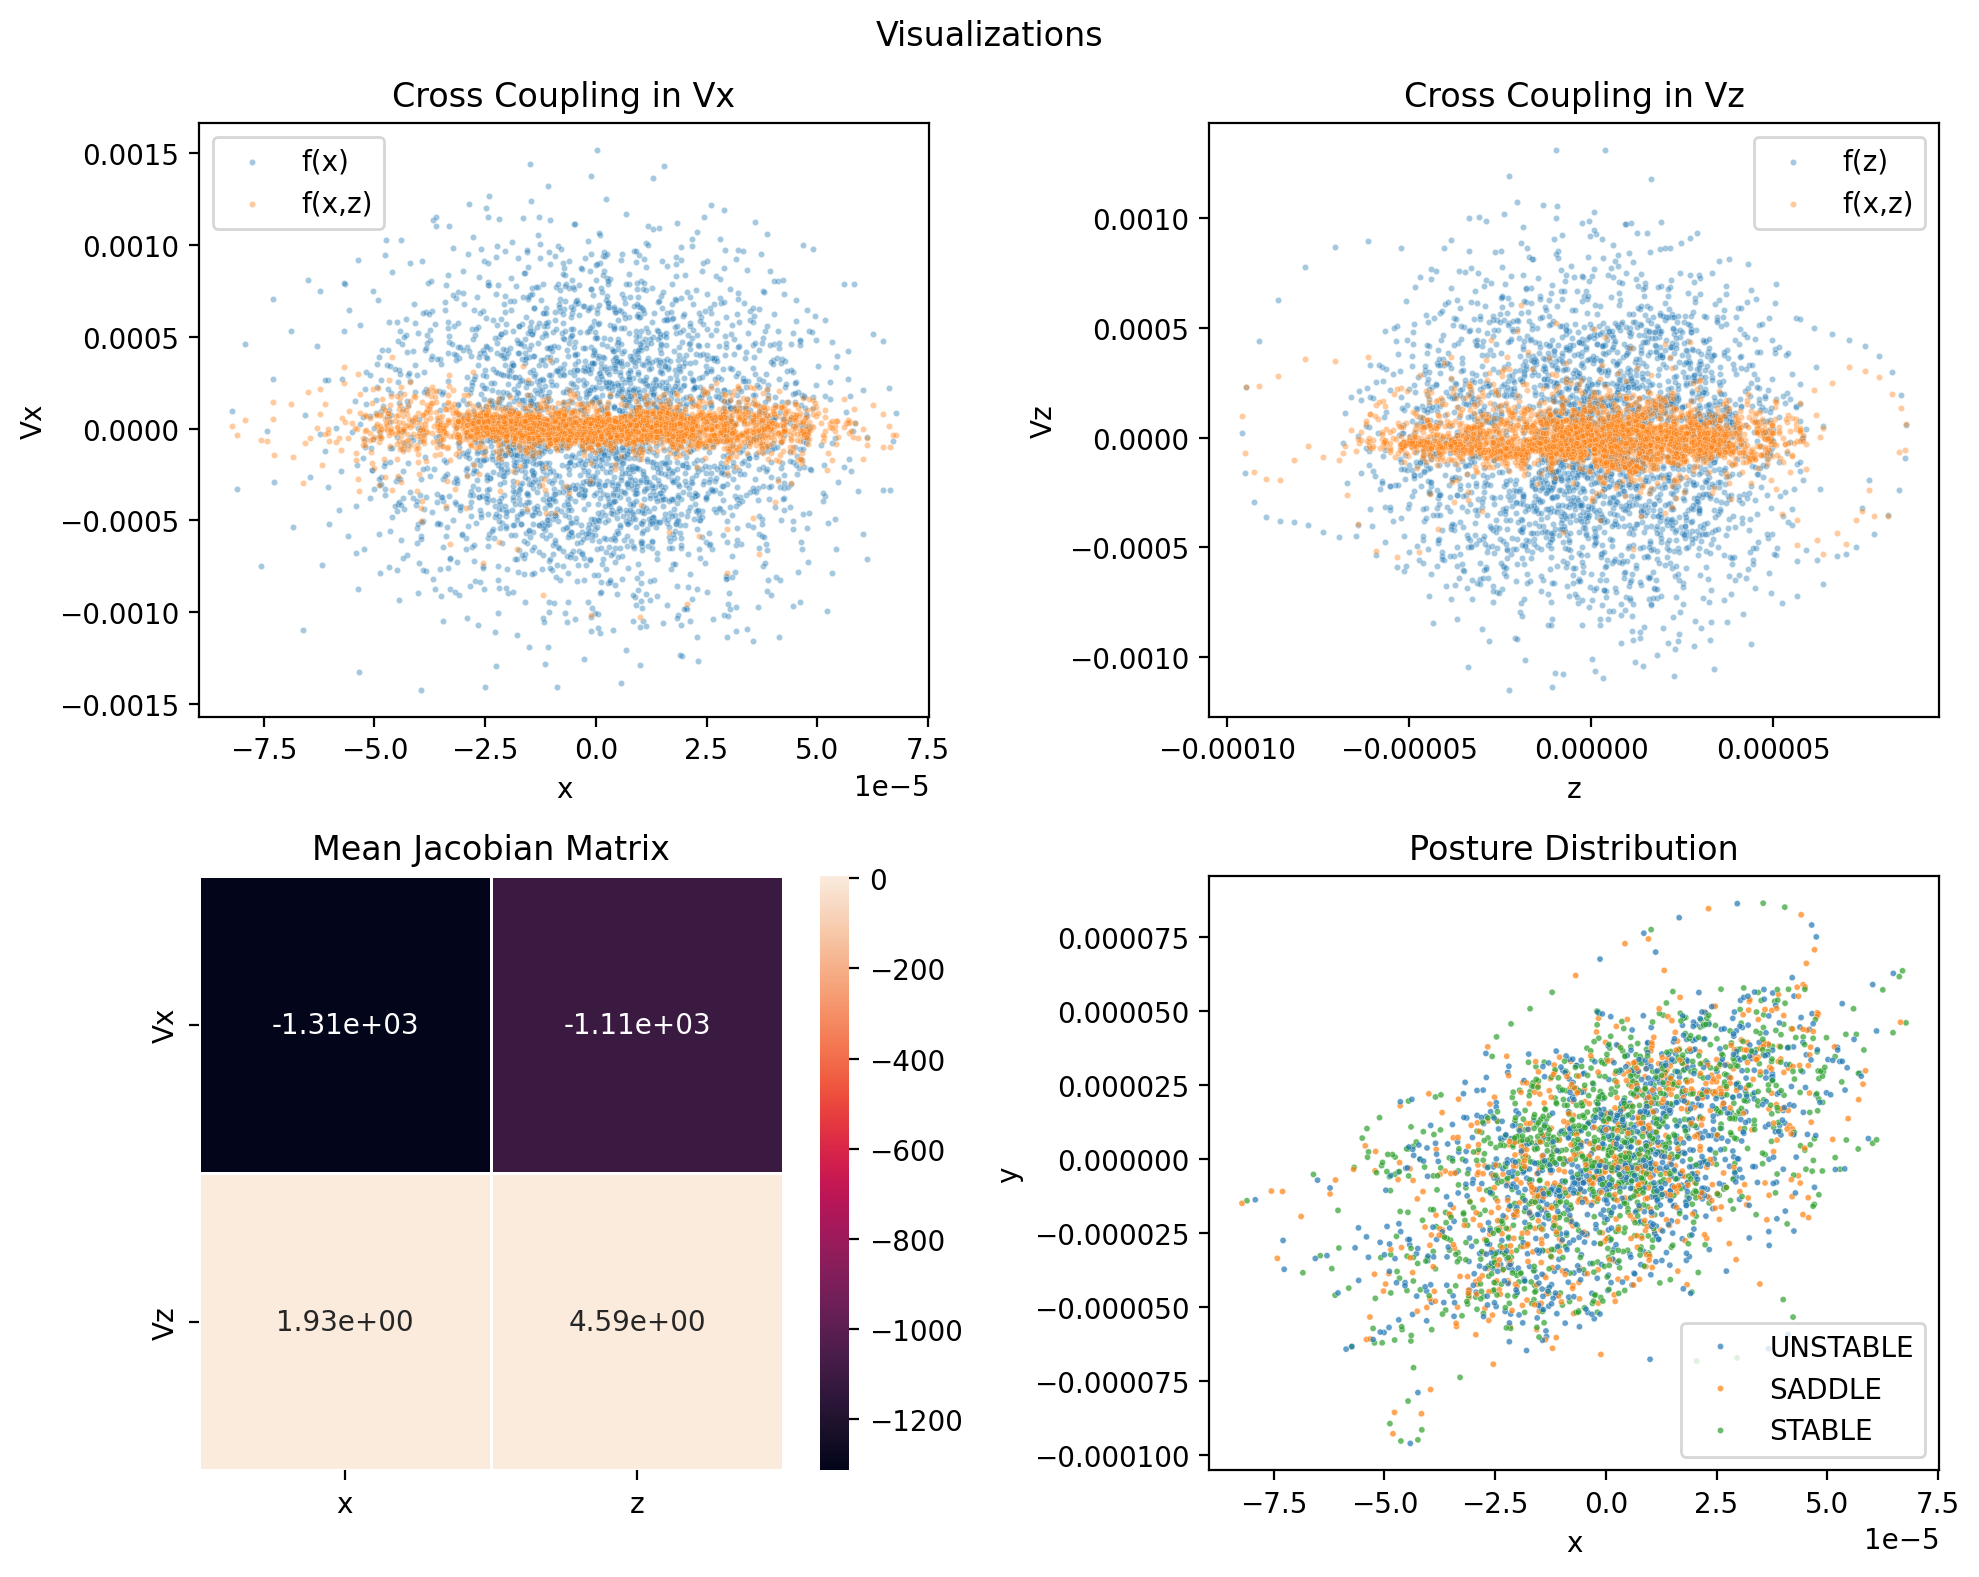

In [250]:
graphs(output)

### Eyes Open & Foam Surface

In [251]:
ind_vel=independent_velocity(test_types[2])
dep_vel_x=dependent_velocity_x(ind_vel)
print(f'Vx (x,y) = {dep_vel_x[1]}')
print(f'Mean Absolute Error: {dep_vel_x[2]}')
print(f'Mean Square Error: {dep_vel_x[3]}')
print(f'Root Mean Square Error: {dep_vel_x[4]}')
print(f'R^2 Score: {dep_vel_x[5]}')

Vx (x,y) = [0.45984324 0.54015676]
Mean Absolute Error: 0.0002887717496817744
Mean Square Error: 1.3326879672784628e-07
Root Mean Square Error: 0.0003650599905876379
R^2 Score: 0.2215774295945273


In [252]:
dep_vel_z=dependent_velocity_z(dep_vel_x[0])
print(f'Vz (x,y) = {dep_vel_z[1]}')
print(f'Mean Absolute Error: {dep_vel_z[2]}')
print(f'Mean Square Error: {dep_vel_z[3]}')
print(f'Root Mean Square Error: {dep_vel_z[4]}')
print(f'R^2 Score: {dep_vel_z[5]}')

Vz (x,y) = [0.54593916 0.45406084]
Mean Absolute Error: 0.0002749103500197627
Mean Square Error: 1.2378144297984073e-07
Root Mean Square Error: 0.0003518258702537958
R^2 Score: 0.18616936027995168


In [253]:
jacobian=partial_derivative(dep_vel_z[0])
output=classify_by_eigenvalues(jacobian)

In [254]:
output

,X,Z,Vx,Vz,dVx,dVz,Vx/X,Vz/X,Vx/Z,Vz/Z,Balance
0,0.000070,-0.000040,-0.000622,0.000679,-0.000346,0.000432,-0.934408,-8.876387,0.855604,8.127796,UNSTABLE
1,0.000063,-0.000033,-0.000840,0.000767,-0.000340,0.000487,4.878653,19.015802,-5.342897,-20.825311,STABLE
2,0.000053,-0.000025,-0.001198,0.000883,-0.000428,0.000113,0.876633,17.735975,-1.189093,-24.057648,STABLE
3,0.000039,-0.000015,-0.001399,0.000892,-0.000361,0.000062,-12.552847,-0.002234,19.686009,0.003503,SADDLE
4,0.000025,-0.000007,-0.001450,0.000824,-0.000076,0.000113,-9.143117,1.393454,16.092927,-2.452638,SADDLE
...,...,...,...,...,...,...,...,...,...,...,...
2971,-0.000035,-0.000012,-0.000443,-0.000219,-0.000046,0.000083,-2.223554,2.569760,-4.495263,5.195173,UNSTABLE
2972,-0.000040,-0.000014,-0.000394,-0.000078,-0.000042,-0.000031,2.708716,13.558783,13.749382,68.824066,UNSTABLE
2973,-0.000043,-0.000014,-0.000307,0.000051,-0.000067,-0.000024,2.547230,-6.264144,-15.406196,37.886894,UNSTABLE
2974,-0.000046,-0.000013,-0.000196,0.000161,-0.000058,0.000007,-11.191408,-5.643020,13.628675,6.871959,STABLE


In [255]:
output["Balance"].value_counts()

Balance
STABLE      1131
UNSTABLE    1107
SADDLE       738
Name: count, dtype: int64

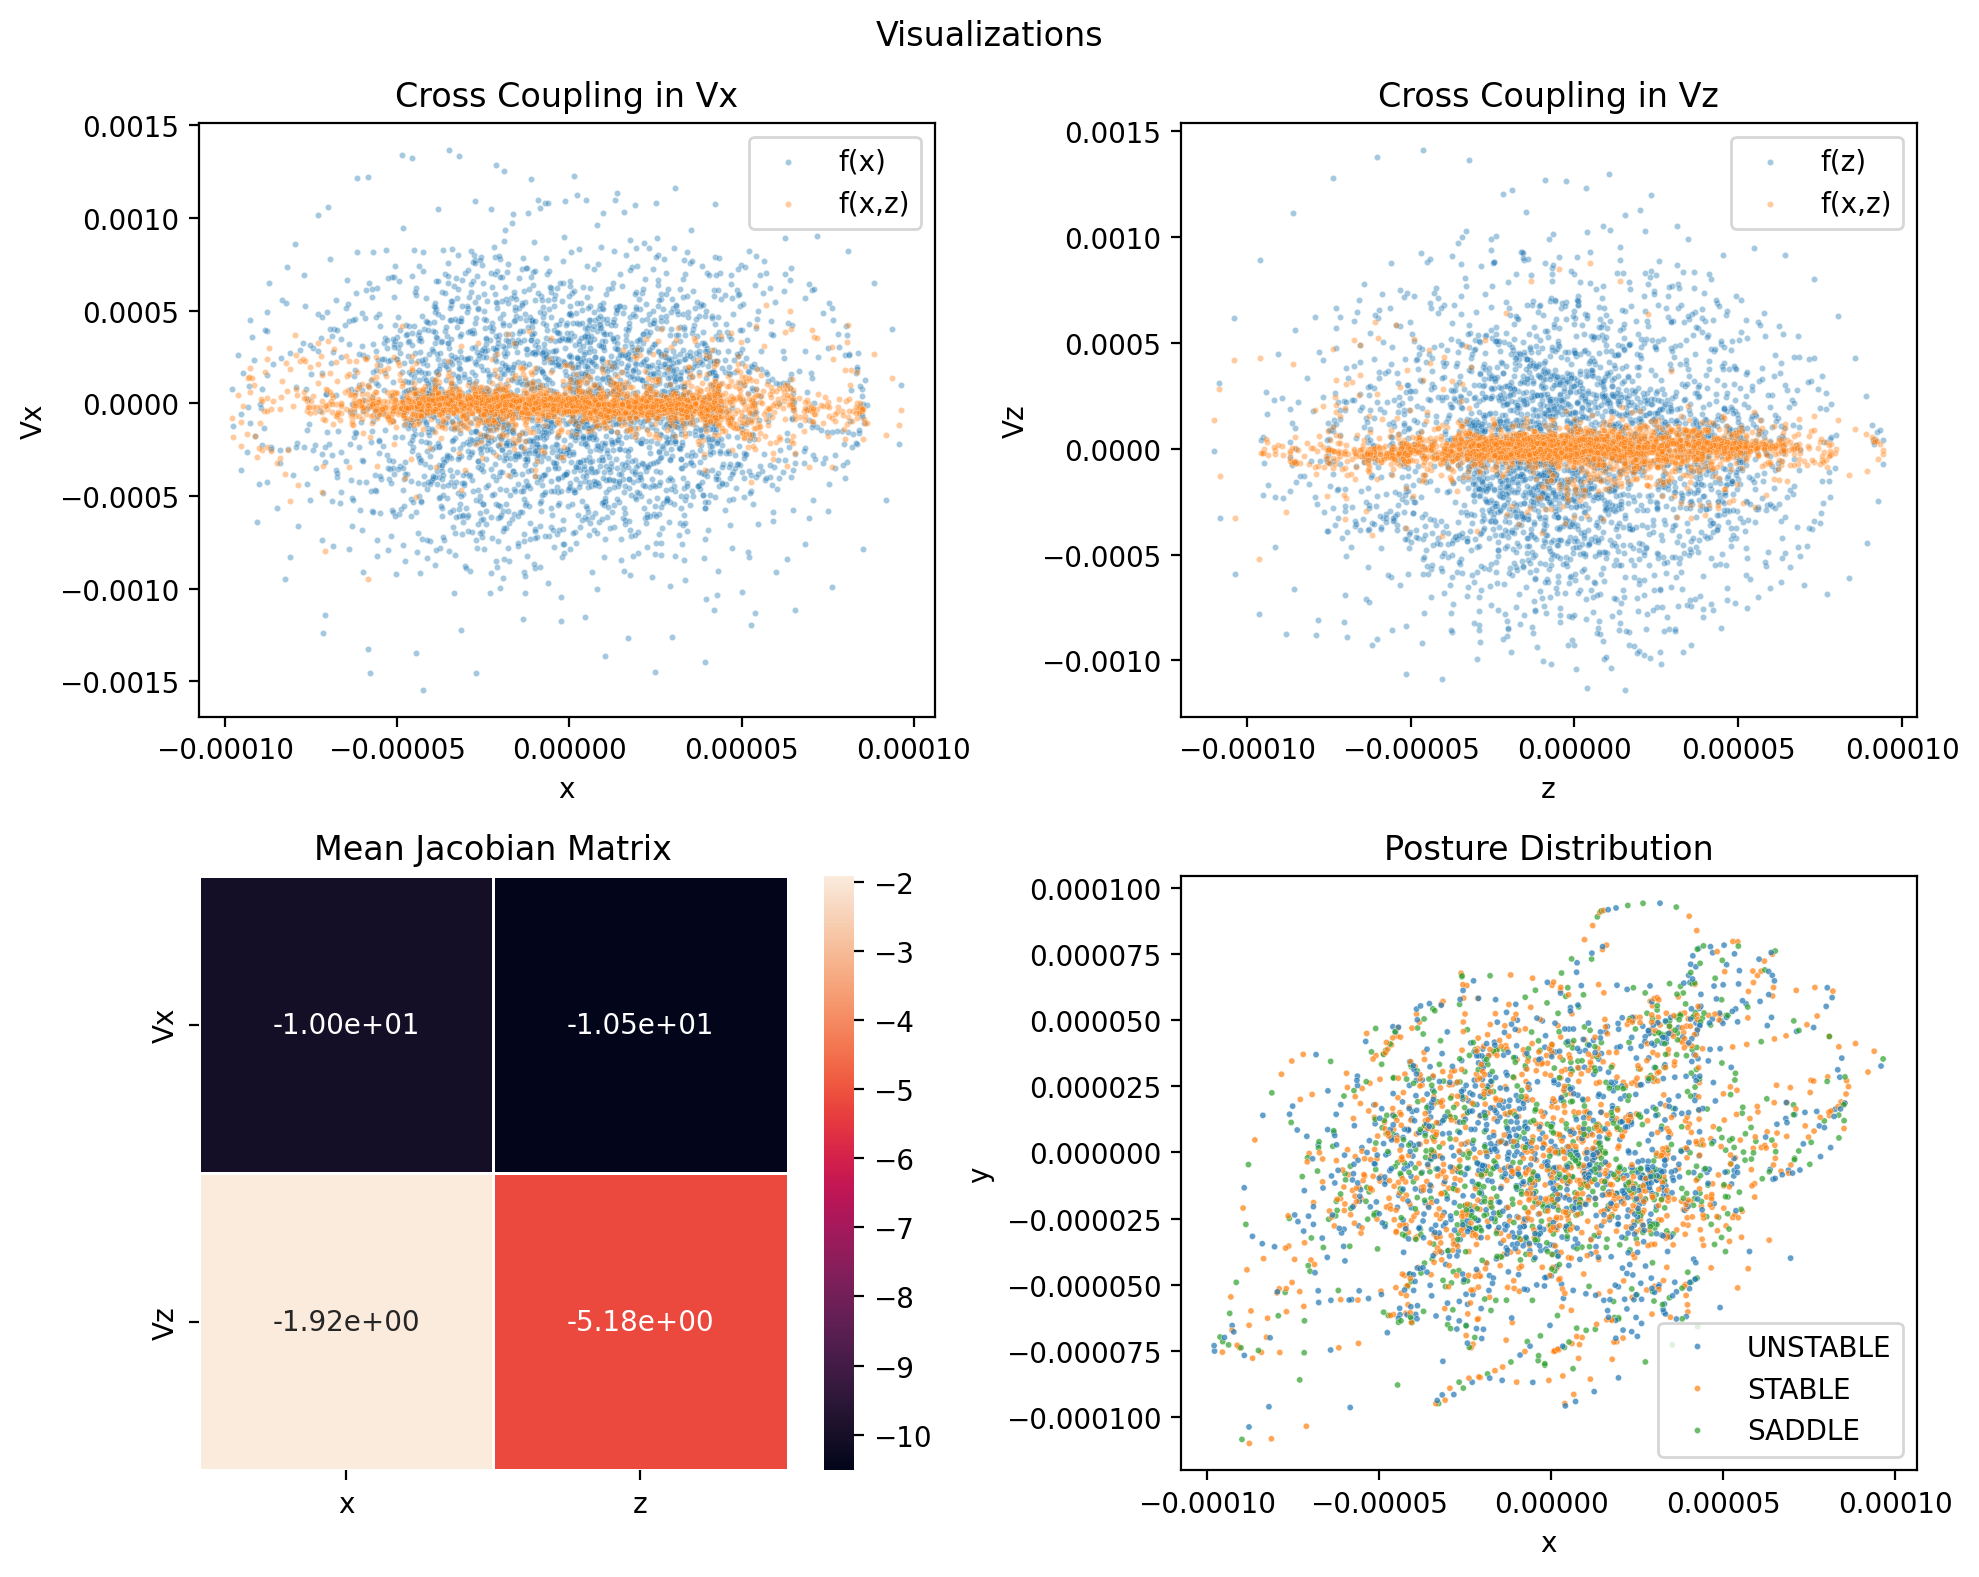

In [256]:
graphs(output)

### Eyes Closed & Foam Surface

In [257]:
ind_vel=independent_velocity(test_types[3])
dep_vel_x=dependent_velocity_x(ind_vel)
print(f'Vx (x,y) = {dep_vel_x[1]}')
print(f'Mean Absolute Error: {dep_vel_x[2]}')
print(f'Mean Square Error: {dep_vel_x[3]}')
print(f'Root Mean Square Error: {dep_vel_x[4]}')
print(f'R^2 Score: {dep_vel_x[5]}')

Vx (x,y) = [0.47268815 0.52731185]
Mean Absolute Error: 0.0002884859368334048
Mean Square Error: 1.3334193218142326e-07
Root Mean Square Error: 0.0003651601459379477
R^2 Score: 0.2568594186530493


In [258]:
dep_vel_z=dependent_velocity_z(dep_vel_x[0])
print(f'Vz (x,y) = {dep_vel_z[1]}')
print(f'Mean Absolute Error: {dep_vel_z[2]}')
print(f'Mean Square Error: {dep_vel_z[3]}')
print(f'Root Mean Square Error: {dep_vel_z[4]}')
print(f'R^2 Score: {dep_vel_z[5]}')

Vz (x,y) = [0.54520236 0.45479764]
Mean Absolute Error: 0.00028210617591250875
Mean Square Error: 1.287550465064209e-07
Root Mean Square Error: 0.0003588245344265368
R^2 Score: 0.307185827571126


In [259]:
jacobian=partial_derivative(dep_vel_z[0])
output=classify_by_eigenvalues(jacobian)

In [260]:
output

,X,Z,Vx,Vz,dVx,dVz,Vx/X,Vz/X,Vx/Z,Vz/Z,Balance
0,0.000051,-9.933300e-05,-0.001376,0.000493,-0.000724,-0.000038,-11.796953,-27.453347,32.952201,76.684904,SADDLE
1,0.000037,-9.440725e-05,-0.001515,0.000766,-0.000561,0.000340,-9.648672,-9.877488,19.093358,19.546153,UNSTABLE
2,0.000020,-8.401791e-05,-0.001716,0.001186,-0.000431,0.000261,0.505446,6.657625,-0.731100,-9.629901,SADDLE
3,0.000002,-7.068051e-05,-0.001772,0.001365,-0.000579,0.000111,3.948967,5.051787,-5.128879,-6.561210,SADDLE
4,-0.000015,-5.672627e-05,-0.001705,0.001336,-0.000571,0.000082,-1.203563,0.429044,1.535682,-0.547437,STABLE
...,...,...,...,...,...,...,...,...,...,...,...
2971,-0.000107,6.242821e-07,-0.000626,-0.000368,-0.000299,-0.000352,-3.963388,11.463870,-6.734272,19.478491,UNSTABLE
2972,-0.000113,-3.299368e-06,-0.000519,-0.000390,-0.000227,-0.000332,-15.304343,1.985071,-20.396895,2.645608,STABLE
2973,-0.000117,-7.168907e-06,-0.000352,-0.000358,-0.000140,-0.000372,-20.342485,-0.558094,-20.004082,-0.548810,STABLE
2974,-0.000120,-1.045337e-05,-0.000135,-0.000286,-0.000084,-0.000329,-32.658018,-27.889891,-15.451910,-13.195905,STABLE


In [261]:
output["Balance"].value_counts()

Balance
UNSTABLE    1147
STABLE      1119
SADDLE       710
Name: count, dtype: int64

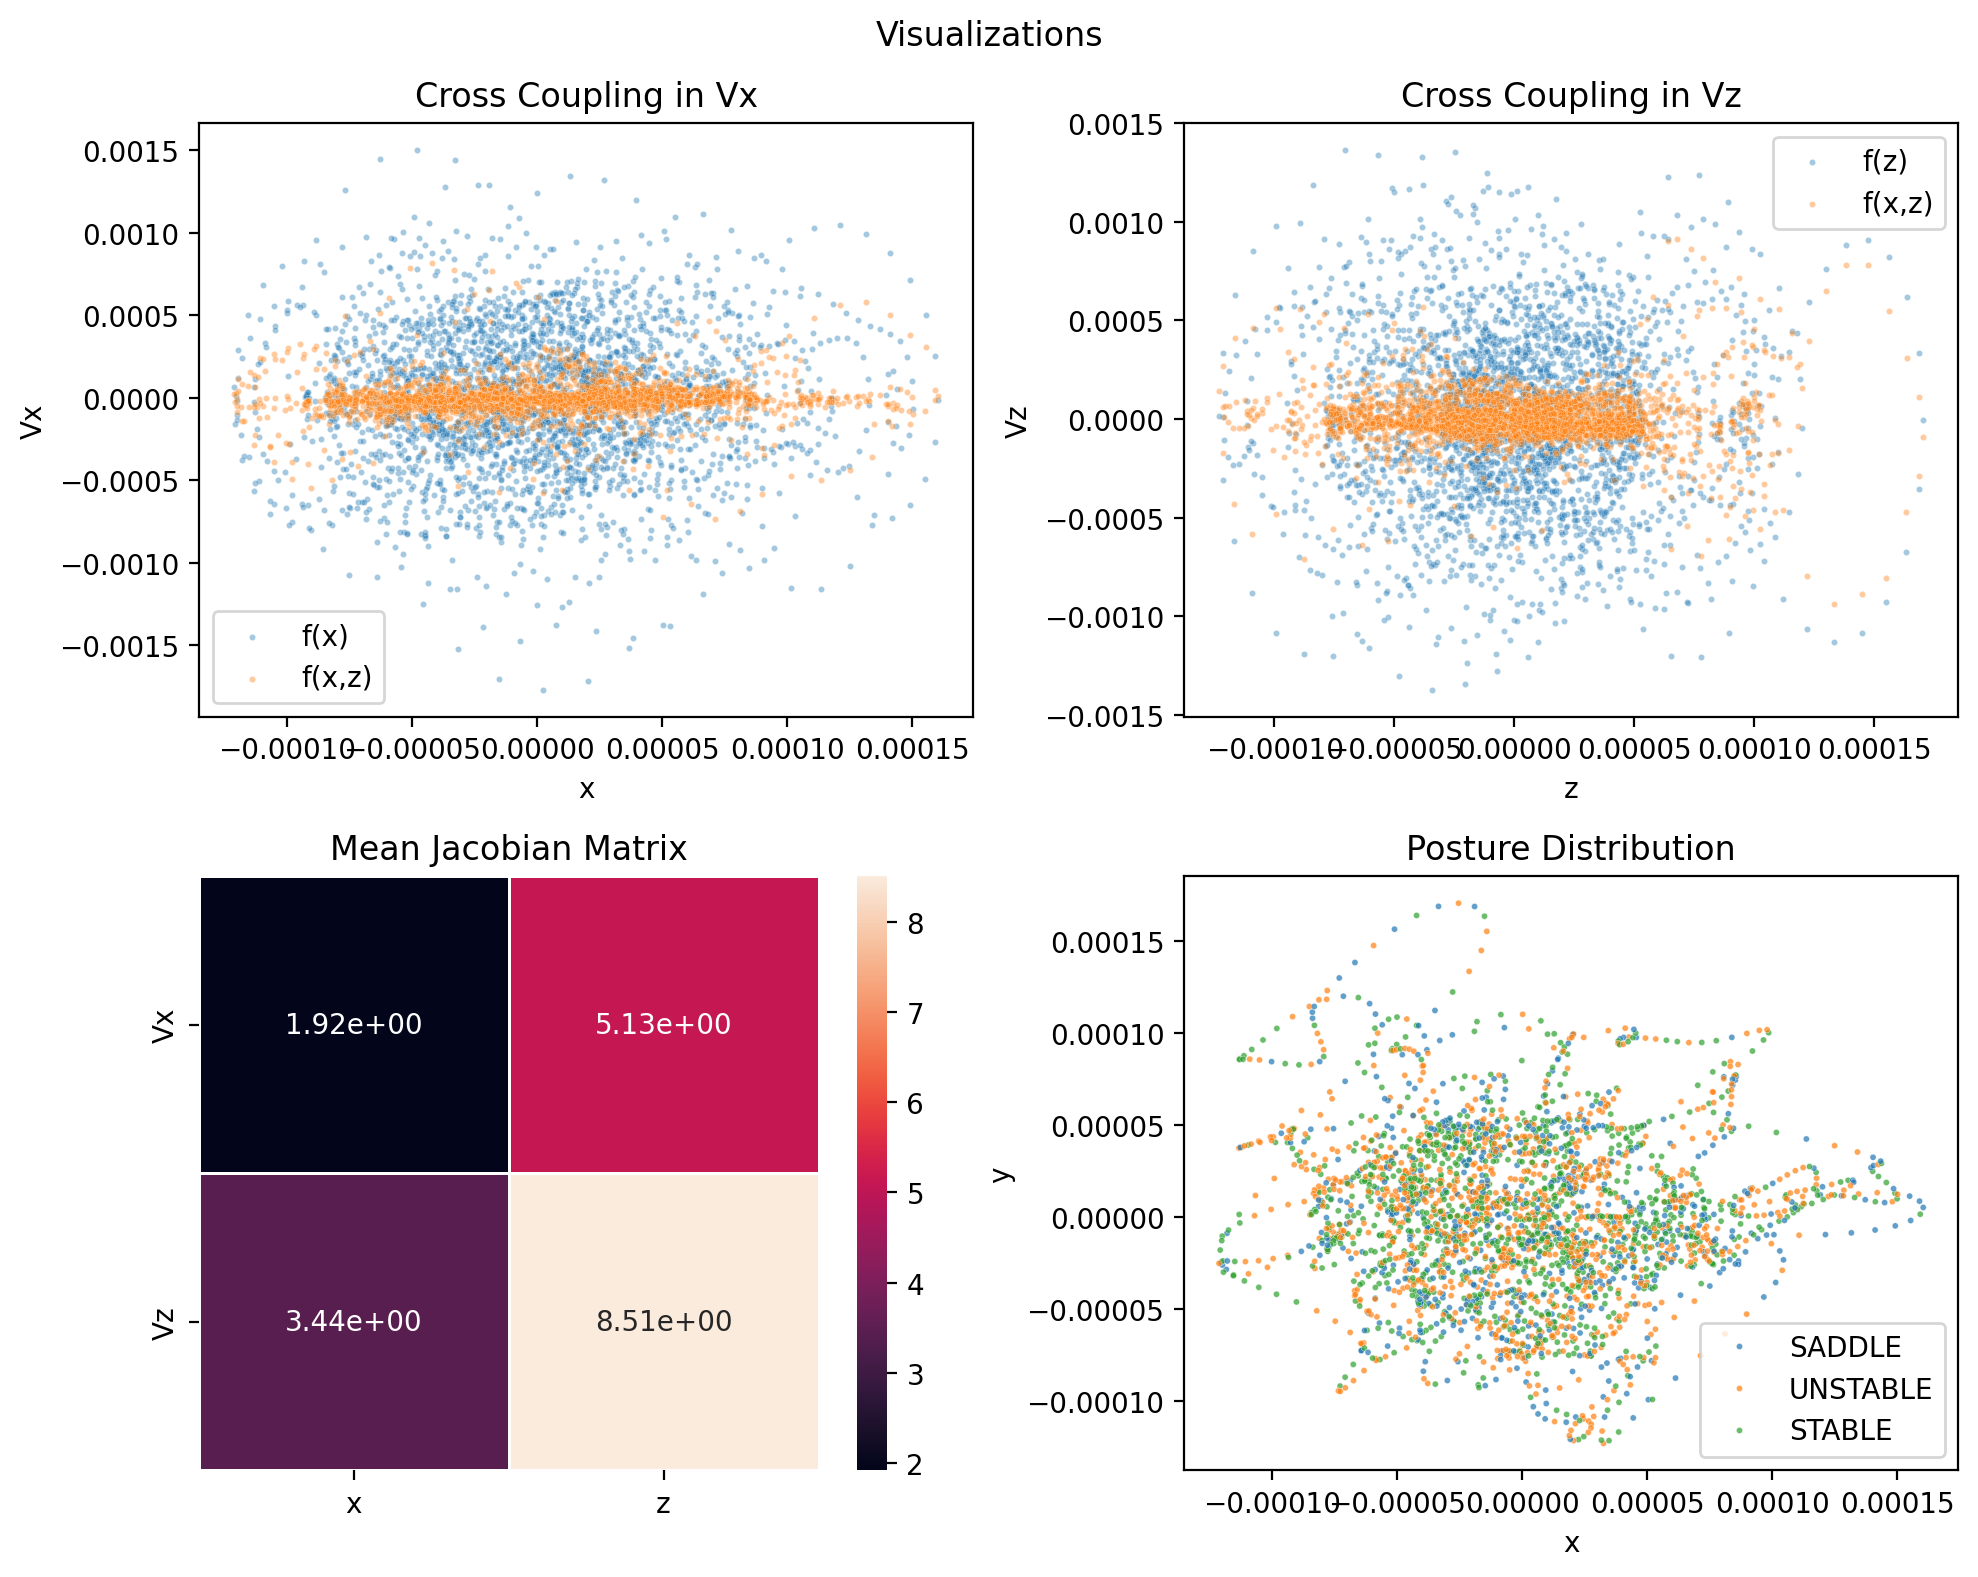

In [262]:
graphs(output)

## Patient2

In [263]:
test_types=patient_test_type_split(p2)

### Eyes Open & Firm Surface 

In [264]:
ind_vel=independent_velocity(test_types[0])
dep_vel_x=dependent_velocity_x(ind_vel)
print(f'Vx (x,y) = {dep_vel_x[1]}')
print(f'Mean Absolute Error: {dep_vel_x[2]}')
print(f'Mean Square Error: {dep_vel_x[3]}')
print(f'Root Mean Square Error: {dep_vel_x[4]}')
print(f'R^2 Score: {dep_vel_x[5]}')

Vx (x,y) = [0.4039056 0.5960944]
Mean Absolute Error: 0.00028348770689246906
Mean Square Error: 1.2613062334086632e-07
Root Mean Square Error: 0.0003551487341113105
R^2 Score: 0.2499643099566461


In [265]:
dep_vel_z=dependent_velocity_z(dep_vel_x[0])
print(f'Vz (x,y) = {dep_vel_z[1]}')
print(f'Mean Absolute Error: {dep_vel_z[2]}')
print(f'Mean Square Error: {dep_vel_z[3]}')
print(f'Root Mean Square Error: {dep_vel_z[4]}')
print(f'R^2 Score: {dep_vel_z[5]}')

Vz (x,y) = [0.3525462 0.6474538]
Mean Absolute Error: 0.00025591261858207604
Mean Square Error: 1.1369198727837798e-07
Root Mean Square Error: 0.0003371824243319601
R^2 Score: 0.3707535420645067


In [266]:
jacobian=partial_derivative(dep_vel_z[0])
output=classify_by_eigenvalues(jacobian)

In [267]:
output

,X,Z,Vx,Vz,dVx,dVz,Vx/X,Vz/X,Vx/Z,Vz/Z,Balance
0,0.000077,0.000307,-0.000666,-0.002791,-0.000773,-0.003246,8.932434,29.481992,2.130781,7.032759,UNSTABLE
1,0.000070,0.000279,-0.000871,-0.003591,-0.000833,-0.003442,14.841601,55.573564,3.598819,13.475583,UNSTABLE
2,0.000060,0.000235,-0.001160,-0.004789,-0.001032,-0.004213,7.207823,31.913310,1.745755,7.729494,UNSTABLE
3,0.000047,0.000184,-0.001220,-0.005228,-0.001000,-0.004182,-16.935028,-30.450370,-3.952485,-7.106845,STABLE
4,0.000035,0.000131,-0.001094,-0.005028,-0.000618,-0.003470,-35.939842,-60.984746,-7.821440,-13.271859,STABLE
...,...,...,...,...,...,...,...,...,...,...,...
2971,-0.000003,0.000050,-0.000152,0.000248,-0.000016,0.000143,15.664470,15.251900,-9.597663,-9.344880,UNSTABLE
2972,-0.000005,0.000053,-0.000210,0.000202,-0.000019,0.000061,1.234117,26.324373,-1.284196,-27.392567,STABLE
2973,-0.000007,0.000054,-0.000268,0.000131,-0.000022,0.000033,14.675534,15.267426,-29.925144,-31.132083,STABLE
2974,-0.000010,0.000055,-0.000290,0.000068,-0.000098,-0.000021,17.695897,12.175325,-75.134814,-51.695077,SADDLE


In [268]:
output["Balance"].value_counts()

Balance
STABLE      1155
UNSTABLE    1104
SADDLE       717
Name: count, dtype: int64

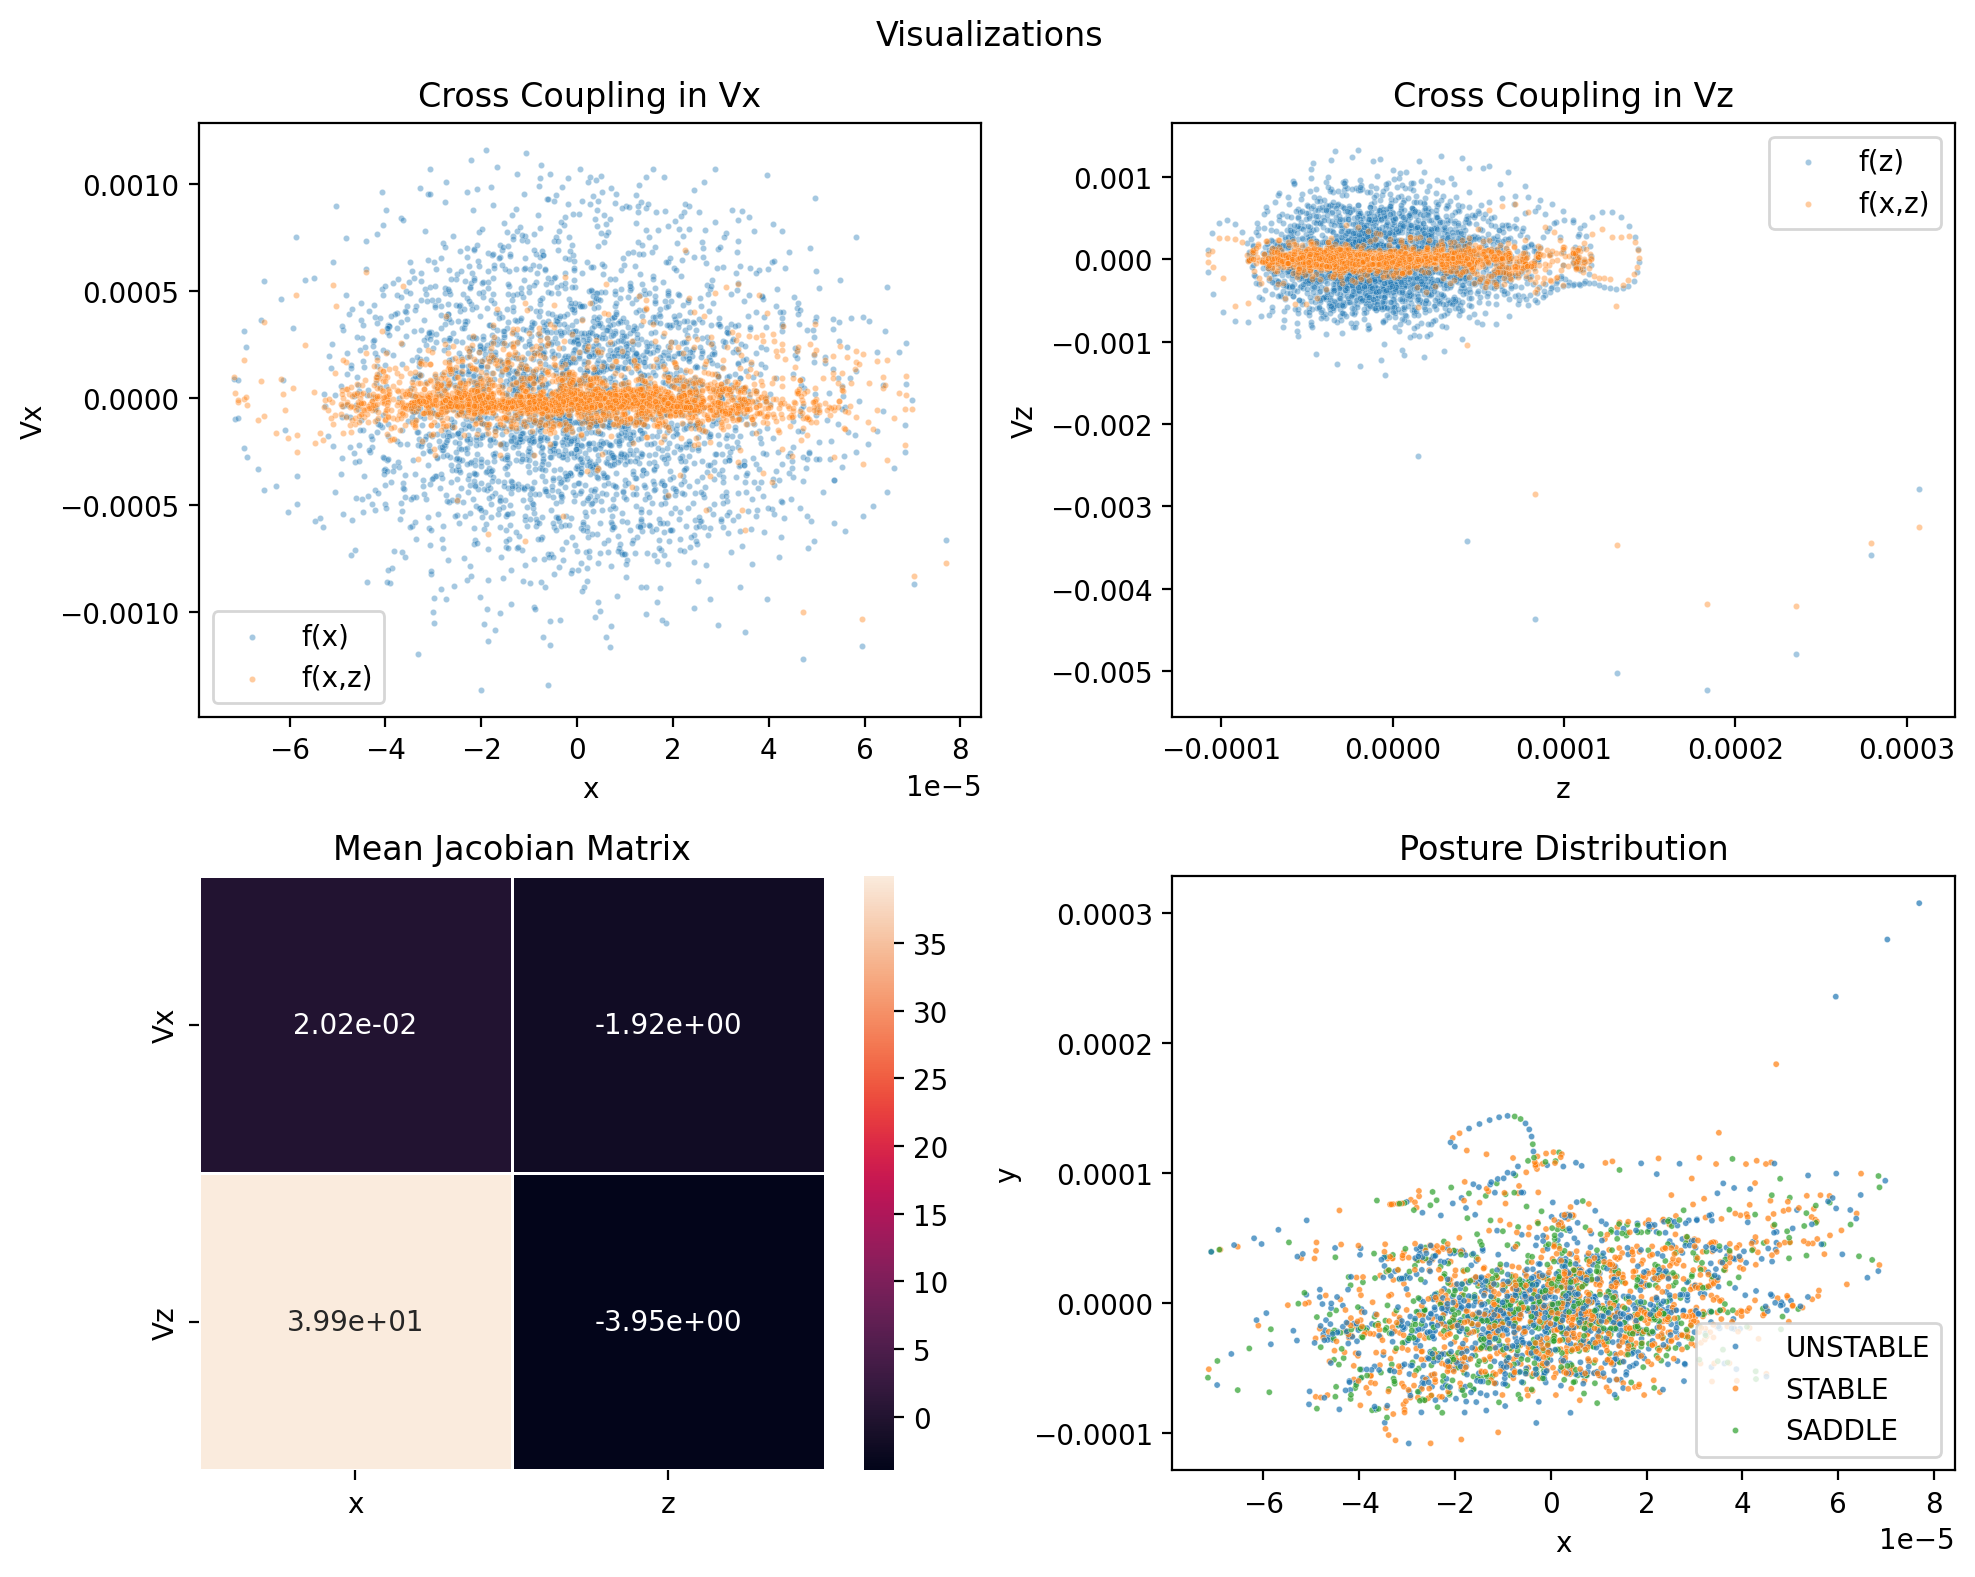

In [269]:
graphs(output)

### Eyes Closed & Firm Surface

In [270]:
ind_vel=independent_velocity(test_types[1])
dep_vel_x=dependent_velocity_x(ind_vel)
print(f'Vx (x,y) = {dep_vel_x[1]}')
print(f'Mean Absolute Error: {dep_vel_x[2]}')
print(f'Mean Square Error: {dep_vel_x[3]}')
print(f'Root Mean Square Error: {dep_vel_x[4]}')
print(f'R^2 Score: {dep_vel_x[5]}')

Vx (x,y) = [0.45101541 0.54898459]
Mean Absolute Error: 0.00026594228185744783
Mean Square Error: 1.1189307265756324e-07
Root Mean Square Error: 0.0003345042191924688
R^2 Score: 0.2699275685760516


In [271]:
dep_vel_z=dependent_velocity_z(dep_vel_x[0])
print(f'Vz (x,y) = {dep_vel_z[1]}')
print(f'Mean Absolute Error: {dep_vel_z[2]}')
print(f'Mean Square Error: {dep_vel_z[3]}')
print(f'Root Mean Square Error: {dep_vel_z[4]}')
print(f'R^2 Score: {dep_vel_z[5]}')

Vz (x,y) = [0.53361371 0.46638629]
Mean Absolute Error: 0.00027084765459323205
Mean Square Error: 1.2057172296868607e-07
Root Mean Square Error: 0.000347234391972751
R^2 Score: 0.2226584484955193


In [272]:
jacobian=partial_derivative(dep_vel_z[0])
output=classify_by_eigenvalues(jacobian)

In [273]:
output

,X,Z,Vx,Vz,dVx,dVz,Vx/X,Vz/X,Vx/Z,Vz/Z,Balance
0,-0.000054,0.000013,0.001422,-0.000296,0.000745,-0.000150,-16.122106,5.460818,77.556634,-26.269688,STABLE
1,-0.000040,0.000010,0.001502,-0.000476,0.000515,-0.000073,-19.379088,2.281727,61.147383,-7.199598,STABLE
2,-0.000024,0.000003,0.001578,-0.000770,0.000162,-0.000082,-11.206650,1.356430,22.958942,-2.778904,STABLE
3,-0.000009,-0.000006,0.001489,-0.000935,0.000162,-0.000030,-0.596210,-0.389213,0.949738,0.620000,UNSTABLE
4,0.000005,-0.000016,0.001266,-0.000981,0.000144,-0.000093,-1.127433,1.669563,1.455776,-2.155791,STABLE
...,...,...,...,...,...,...,...,...,...,...,...
2971,0.000048,0.000041,-0.000084,0.000023,-0.000034,0.000001,2.956909,-1.576675,-10.849298,5.785034,UNSTABLE
2972,0.000047,0.000041,-0.000099,-0.000027,-0.000043,0.000009,1.495892,-0.739621,5.588359,-2.763079,SADDLE
2973,0.000046,0.000040,-0.000103,-0.000061,-0.000037,0.000003,-9.789180,3.025881,-16.417355,5.074680,STABLE
2974,0.000045,0.000040,-0.000103,-0.000090,-0.000023,0.000002,-19.567145,2.992905,-22.319971,3.413966,STABLE


In [274]:
output["Balance"].value_counts()

Balance
UNSTABLE    1124
STABLE      1113
SADDLE       739
Name: count, dtype: int64

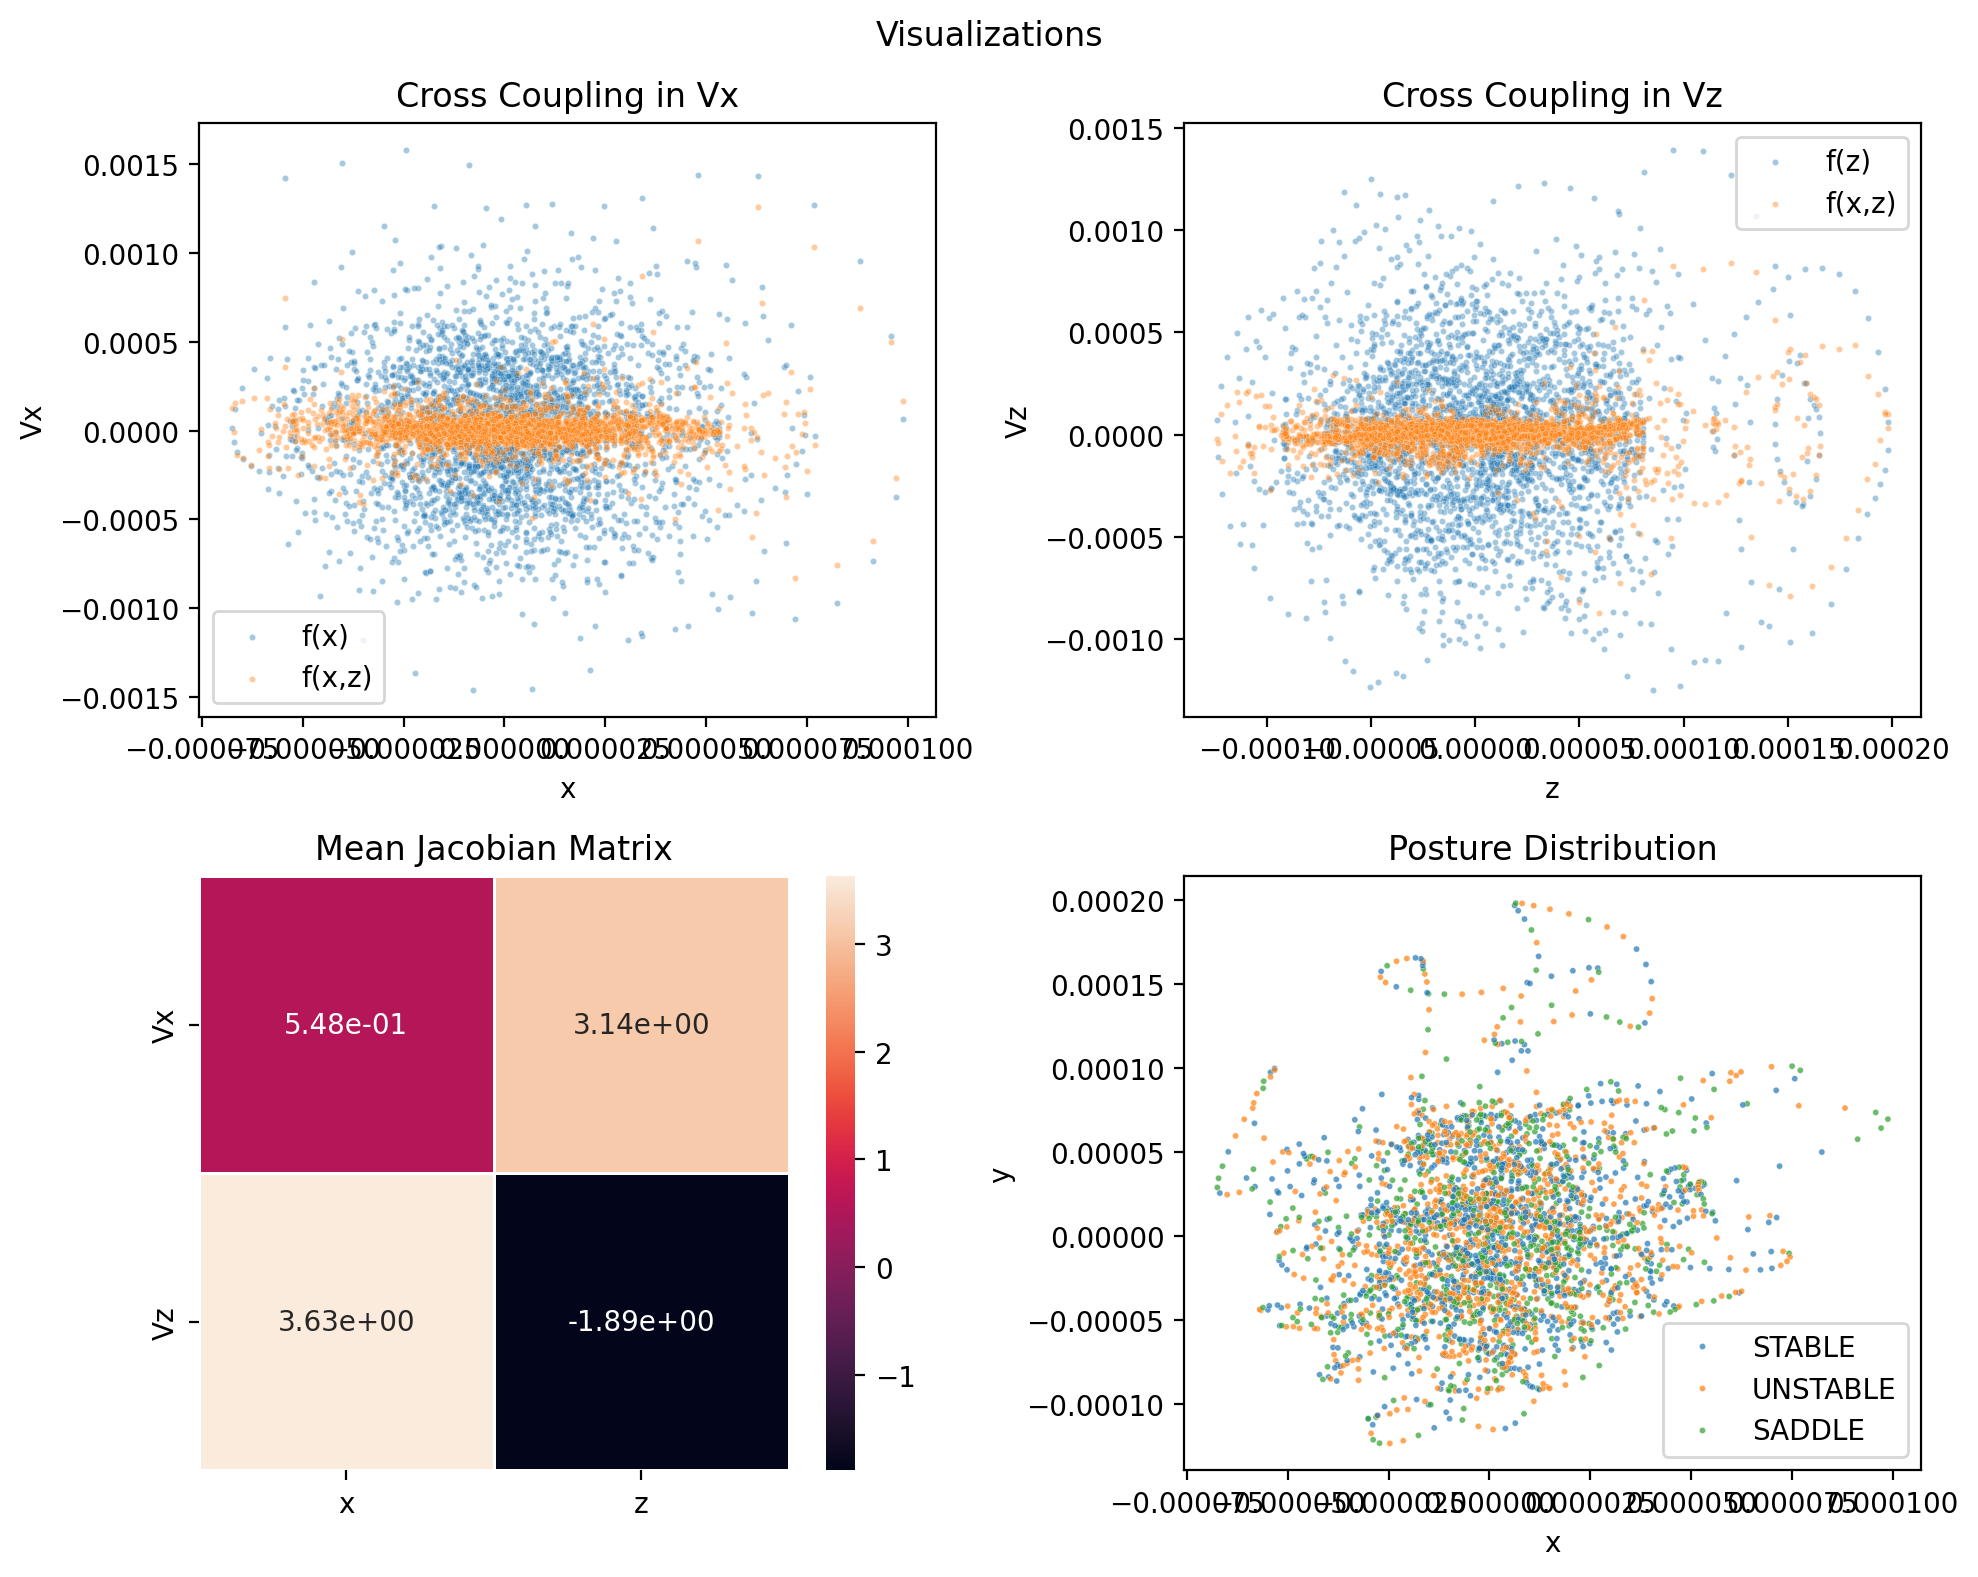

In [275]:
graphs(output)

### Eyes Open & Foam Surface

In [276]:
ind_vel=independent_velocity(test_types[2])
dep_vel_x=dependent_velocity_x(ind_vel)
print(f'Vx (x,y) = {dep_vel_x[1]}')
print(f'Mean Absolute Error: {dep_vel_x[2]}')
print(f'Mean Square Error: {dep_vel_x[3]}')
print(f'Root Mean Square Error: {dep_vel_x[4]}')
print(f'R^2 Score: {dep_vel_x[5]}')

Vx (x,y) = [0.49834876 0.50165124]
Mean Absolute Error: 0.0002717238969129375
Mean Square Error: 1.2359101647214042e-07
Root Mean Square Error: 0.00035155514001666995
R^2 Score: 0.23887066449199457


In [277]:
dep_vel_z=dependent_velocity_z(dep_vel_x[0])
print(f'Vz (x,y) = {dep_vel_z[1]}')
print(f'Mean Absolute Error: {dep_vel_z[2]}')
print(f'Mean Square Error: {dep_vel_z[3]}')
print(f'Root Mean Square Error: {dep_vel_z[4]}')
print(f'R^2 Score: {dep_vel_z[5]}')

Vz (x,y) = [0.55524762 0.44475238]
Mean Absolute Error: 0.0003211155260011286
Mean Square Error: 1.601705727845254e-07
Root Mean Square Error: 0.0004002131591846093
R^2 Score: 0.22731507222691505


In [278]:
jacobian=partial_derivative(dep_vel_z[0])
output=classify_by_eigenvalues(jacobian)

In [279]:
output

,X,Z,Vx,Vz,dVx,dVz,Vx/X,Vz/X,Vx/Z,Vz/Z,Balance
0,1.257263e-04,-0.000063,-0.001513,0.000420,-0.001455,0.000414,13.781543,-1.142547,-49.594020,4.111548,UNSTABLE
1,1.105965e-04,-0.000058,-0.002035,0.000460,-0.001663,0.000432,7.967810,-0.480436,-35.254190,2.125725,UNSTABLE
2,8.502524e-05,-0.000053,-0.002820,0.000540,-0.001779,0.000434,-10.139928,4.308950,52.980007,-22.513788,STABLE
3,5.419870e-05,-0.000048,-0.003129,0.000588,-0.001091,0.000189,-19.104007,6.145685,101.626134,-32.692732,STABLE
4,2.244381e-05,-0.000042,-0.003058,0.000559,-0.000584,0.000049,-13.189120,2.750582,72.207172,-15.058754,STABLE
...,...,...,...,...,...,...,...,...,...,...,...
2971,-6.524510e-06,-0.000046,0.000052,-0.000114,0.000035,-0.000015,32.812787,-0.473883,-14.848535,0.214443,UNSTABLE
2972,-5.870668e-06,-0.000047,0.000098,-0.000026,0.000039,-0.000008,1.556947,6.261886,-5.939701,-23.888881,SADDLE
2973,-4.568015e-06,-0.000047,0.000176,0.000112,0.000038,-0.000003,4.098191,-0.849296,6.435861,-1.333747,UNSTABLE
2974,-2.347254e-06,-0.000045,0.000275,0.000287,0.000053,-0.000011,0.656769,5.278145,0.628475,5.050764,UNSTABLE


In [280]:
output["Balance"].value_counts()

Balance
STABLE      1162
UNSTABLE    1071
SADDLE       743
Name: count, dtype: int64

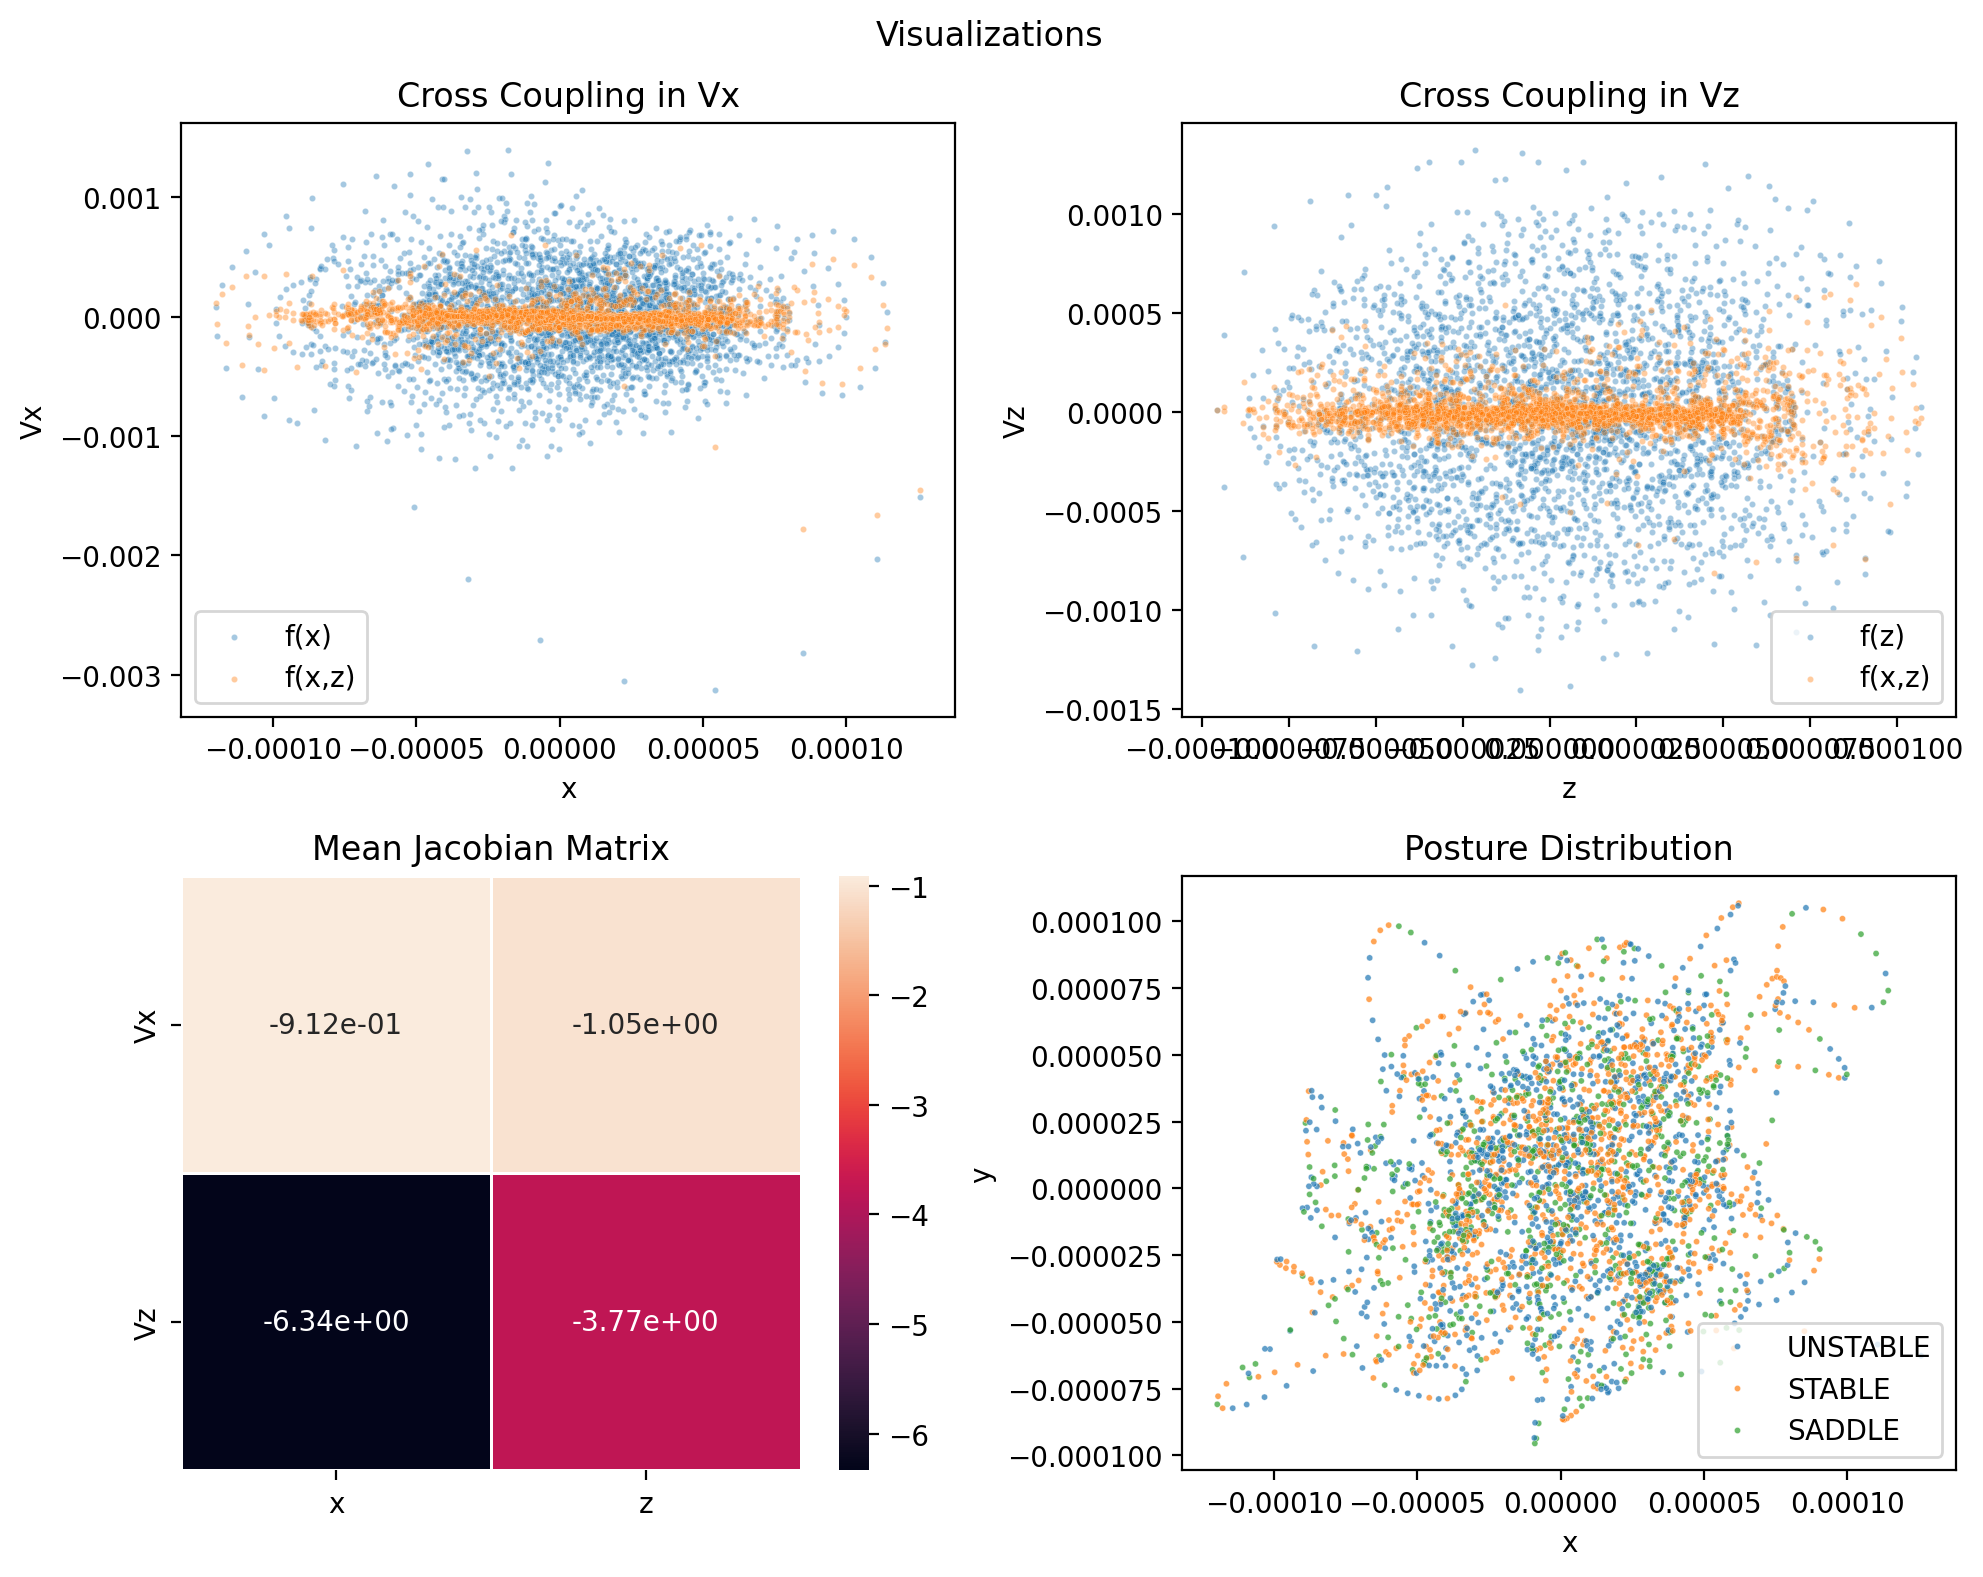

In [281]:
graphs(output)

### Eyes Closed & Foam Surface 

In [282]:
ind_vel=independent_velocity(test_types[3])
dep_vel_x=dependent_velocity_x(ind_vel)
print(f'Vx (x,y) = {dep_vel_x[1]}')
print(f'Mean Absolute Error: {dep_vel_x[2]}')
print(f'Mean Square Error: {dep_vel_x[3]}')
print(f'Root Mean Square Error: {dep_vel_x[4]}')
print(f'R^2 Score: {dep_vel_x[5]}')

Vx (x,y) = [0.48113444 0.51886556]
Mean Absolute Error: 0.00035482827510829114
Mean Square Error: 1.996149675595836e-07
Root Mean Square Error: 0.000446782908759482
R^2 Score: 0.27104546847233413


In [283]:
dep_vel_z=dependent_velocity_z(dep_vel_x[0])
print(f'Vz (x,y) = {dep_vel_z[1]}')
print(f'Mean Absolute Error: {dep_vel_z[2]}')
print(f'Mean Square Error: {dep_vel_z[3]}')
print(f'Root Mean Square Error: {dep_vel_z[4]}')
print(f'R^2 Score: {dep_vel_z[5]}')

Vz (x,y) = [0.54102252 0.45897748]
Mean Absolute Error: 0.0003158355261297917
Mean Square Error: 1.5958985810024018e-07
Root Mean Square Error: 0.0003994869936559139
R^2 Score: 0.32111485757446934


In [284]:
jacobian=partial_derivative(dep_vel_z[0])
output=classify_by_eigenvalues(jacobian)

In [285]:
output

,X,Z,Vx,Vz,dVx,dVz,Vx/X,Vz/X,Vx/Z,Vz/Z,Balance
0,-0.000072,-8.536423e-05,0.000873,0.001564,0.000139,0.000562,-0.007655,-4.980812,-0.004272,-2.779553,SADDLE
1,-0.000063,-6.971941e-05,0.000931,0.001836,0.000139,0.000518,6.669840,-6.739457,3.380110,-3.415390,UNSTABLE
2,-0.000054,-4.863904e-05,0.000991,0.002254,0.000263,0.000436,-4.734591,-9.739772,-2.081944,-4.282874,STABLE
3,-0.000044,-2.464076e-05,0.000955,0.002420,0.000045,0.000325,-11.220658,-5.142281,-4.430214,-2.030309,STABLE
4,-0.000034,-2.455680e-07,0.000846,0.002342,0.000049,0.000338,-2.414729,-1.652261,-0.872718,-0.597151,SADDLE
...,...,...,...,...,...,...,...,...,...,...,...
2971,0.000017,1.504977e-05,0.000684,0.000898,-0.000077,0.000040,4.521550,3.052289,3.441814,2.323409,SADDLE
2972,0.000021,2.277998e-05,0.000135,0.000622,0.000023,0.000218,19.105395,23.444611,4.138612,5.078574,UNSTABLE
2973,0.000020,2.749179e-05,-0.000386,0.000314,-0.000026,0.000104,13.718229,24.271112,-16.884365,-29.872829,SADDLE
2974,0.000014,2.905368e-05,-0.000812,0.000009,-0.000083,0.000030,4.026233,11.541917,-362.680755,-1039.689302,STABLE


In [286]:
output["Balance"].value_counts()

Balance
UNSTABLE    1141
STABLE      1105
SADDLE       730
Name: count, dtype: int64

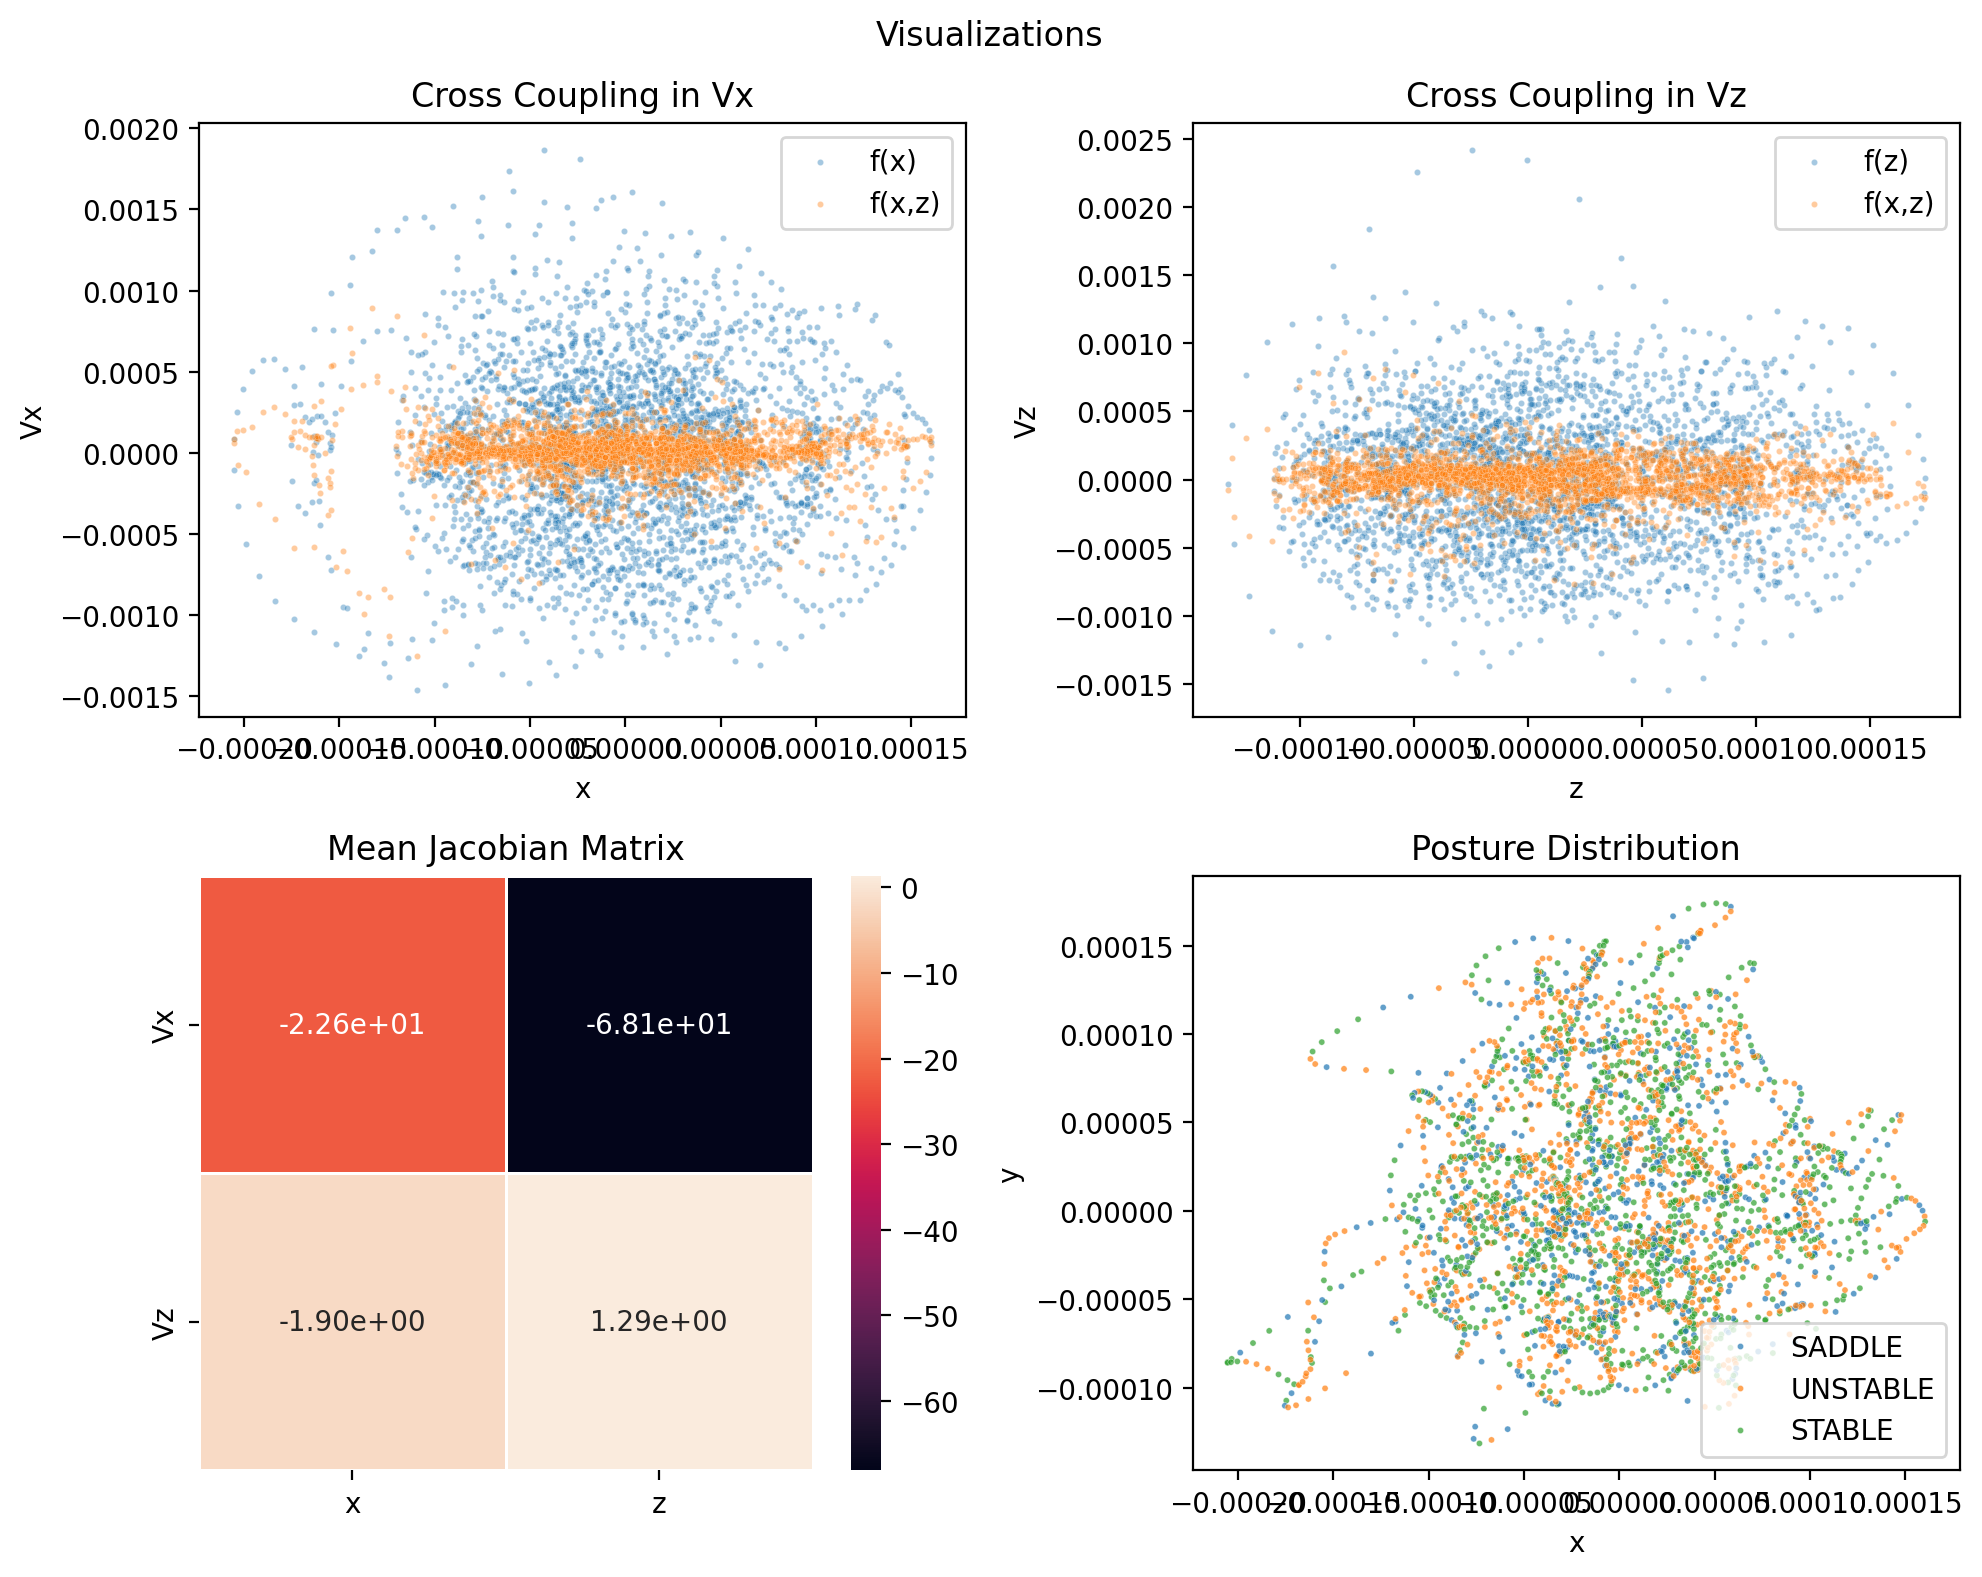

In [287]:
graphs(output)